# Funding, Trials, and Publications in Neuro-Oncology vs. Major Neurology Subspecialties: An Integrated PubMed, NIH RePORTER, and ClinicalTrials.gov Analysis, 2000–2024

Kenzo Revilla, 2026

# Objectives

1. Quantify NIH funding trends by neurology subspecialty (2000–2024), in nominal and inflation-adjusted (BRDPI) dollars.
2. Test whether funding predicts NIH-attributed publication output, and with what lag, using detrended (year-over-year change) series.
3. Compare registered trial activity (ClinicalTrials.gov) with published trials (PubMed) to see whether the early-phase publication signal reflects real pipeline activity.
4. Describe the phase mix of registered neuro-oncology trials (Phase I → II → III) as a proxy for pipeline progression.

# Methods

Data for 2000–2024 were retrieved programmatically from three public APIs: NCBI E-utilities (PubMed), NIH RePORTER v2, and ClinicalTrials.gov v2. 2025 was excluded because PubMed indexing and FY2025 award records were incomplete at the time of extraction.

**Publications.** Ten neurology subspecialties were defined by MeSH-based PubMed queries. Counts were computed for all papers and for NIH-attributed papers (`"nih"[gr]`). A paper matching *k* subspecialties (or *k* neuro-oncology paradigms) was fractionally allocated 1/*k* to each, so no paper is counted more than once.

**Funding.** For the cross-subspecialty comparison, NIH RePORTER awards were retrieved by NIH's official Research, Condition, and Disease Categorization (RCDC) spending categories, available from FY2008 onward. Keyword matching on project titles and terms (FY2000–FY2024) was run as a sensitivity analysis. For the neuro-oncology analyses, keyword matching was used throughout and cross-checked against the RCDC Brain Cancer category.

In all cases, subprojects were excluded, every result page was retrieved, and awards were deduplicated by application ID. An award matching *k* categories was fractionally allocated 1/*k* to each. Annual totals were converted to constant FY2024 dollars with the NIH Biomedical Research and Development Price Index (BRDPI; FY2024 value preliminary).

Alzheimer's disease and related dementias, which receive dedicated congressional appropriations, were retained but reported as a named outlier, with share comparisons shown with and without them.

**Neuro-oncology paradigms.** Within neuro-oncology, grants and NIH-attributed papers were stratified into five methodological paradigms: Surgical/Local, Radiation/Biophysical, Cytotoxic Chemotherapy, Molecular/Genomic, and Immunotherapy/Viral.

**Trials.** Interventional brain-tumor studies registered on ClinicalTrials.gov were tabulated by start year and phase, and compared with PubMed clinical-trial publication types (Phase I, II, III).

**Survival.** SEER 5-year relative survival by year of diagnosis (Brain and Other Nervous System, malignant; SEER 21 excluding Illinois, November 2025 submission) was taken from SEER*Explorer for diagnosis years 2000–2018.

# Data Processing and Reproducibility

All acquisition and processing were performed in Python (requests, pandas, NumPy, SciPy, statsmodels).

Every API response was cached to disk, keyed by its query parameters, so interrupted retrievals resume without repeating completed requests. Requests were rate-limited to each provider's policy (NCBI: 3 requests/s, or 10 with an API key; RePORTER: 1 request/s). Failed requests were retried with exponential backoff, and the run stops if retries are exhausted, rather than silently recording a zero.

PubMed searches returning more than 9,999 records were split into smaller date ranges until complete. Records identified, deduplicated, and included for each source are reported in a PRISMA-style data-flow table at the end of the notebook.

# Statistical Analysis

**Publication growth.** For each subspecialty, growth was modeled with a quasi-Poisson generalized linear model. The model used publication year as the predictor and log(total neurology publications) as an offset, so that each subspecialty's annual growth rate ratio (IRR) is relative to neurology as a whole. Structural shifts were assessed with segmented (piecewise) linear regression, with a single breakpoint chosen by minimum residual error (exploratory).

**Funding and publications.** Inflation-adjusted funding and NIH-attributed publication counts were analyzed as year-over-year changes (first differences, ΔX<sub>t</sub>), which removes the shared upward trend that otherwise produces spurious correlations. Lead-lag Pearson cross-correlations were computed for shifts from −2 to +5 years. Positive lags mean funding leads publications; negative lags mean publications lead funding.

**Directionality.** Granger causality was tested in both directions at lags 1–4, with Holm correction across lags.

**Elasticity.** Funding elasticity (ε) was estimated as the slope of Δlog(publications<sub>t+k</sub>) on Δlog(funding<sub>t</sub>).

**Significance and power.** Significance was set at p < 0.05. With roughly 24 annual observations, power is limited, so lag estimates are reported as exploratory.

In [ ]:
!pip install biopython

import time
import random
import pandas as pd
from Bio import Entrez
from IPython.display import display

# Set random seed as requested
random.seed(42)

# Entrez requires an email address. Replace this with your actual email.
Entrez.email = "your.email@example.com"

# Base query for the denominator
base_query = '"Neurology"[MeSH] OR "Nervous System Diseases"[MeSH]'

# Dictionary of 10 subspecialties with exact search strings
subspecialties = {
   "Neuro-oncology": '"Brain Neoplasms"[MeSH] OR "Central Nervous System Neoplasms"[MeSH] NOT (("Peripheral nerves"[tiab] AND "neoplasms"[MeSH]) OR "Neuroblastoma"[MeSH])',

    "Vascular/Stroke": '"Stroke"[MeSH] OR "Cerebrovascular Disorders"[MeSH] OR "Brain Ischemia"[MeSH] NOT ("Heat Stroke"[MeSH] OR heatstroke[tiab] OR "myocardial infarction"[tiab])',

    "Epilepsy": '"Epilepsy"[MeSH] OR "Seizures"[MeSH] OR "Status Epilepticus"[MeSH] NOT ("Eclampsia"[MeSH] OR "non-epileptic"[tiab] OR "psychogenic"[tiab])',

    "Movement Disorders": '"Movement Disorders"[MeSH] OR "Parkinson Disease"[MeSH] OR "Huntington Disease"[MeSH] NOT ("Bowel movement"[tiab] OR "Eye Movements"[MeSH])',

    "Neuroimmunology": '"Multiple Sclerosis"[MeSH] OR "Autoimmune Diseases of the Nervous System"[MeSH] OR "Encephalomyelitis"[MeSH] NOT "Systemic Lupus Erythematosus"[MeSH:NoExp]',

    "Neuromuscular": '"Neuromuscular Diseases"[MeSH] OR "Motor Neuron Disease"[MeSH] OR "Peripheral Nervous System Diseases"[MeSH] NOT "Neuromuscular Blockade"[MeSH]',

    "Neurocritical Care": '"Neurocritical care"[tiab] OR (("Brain Injuries, Traumatic"[MeSH] OR "Coma"[MeSH]) AND "Intensive Care"[MeSH]) NOT "neonatal intensive care"[tiab]',

    "Cognitive/Behavioral": '"Dementia"[MeSH] OR "Alzheimer Disease"[MeSH] OR "Frontotemporal Lobar Degeneration"[MeSH] NOT ("Schizophrenia"[MeSH] OR "Intellectual Disability"[MeSH])',

    "Headache": '"Headache Disorders"[MeSH] OR "Migraine Disorders"[MeSH] NOT ("dental"[tiab] OR "Sinusitis"[MeSH] OR "Post-Dural Puncture Headache"[MeSH])',

    "Sleep Medicine": '"Sleep Wake Disorders"[MeSH] OR "Narcolepsy"[MeSH] NOT "Anesthesia"[MeSH]'
}

# Helper function to get count for a query in a specific year
def get_pubmed_count(query, year):
    try:
        # Use mindate and maxdate with PDAT (Publication Date) to filter by year
        handle = Entrez.esearch(db="pubmed", term=query, mindate=str(year), maxdate=str(year), datetype="pdat", retmax=0)
        record = Entrez.read(handle)
        handle.close()
        time.sleep(0.35)  # Respect NCBI rate limits
        return int(record["Count"])
    except Exception as e:
        print(f"Error fetching data for {year}: {e}")
        return 0

results = []

# Loop through the years 2000-2025
print("Starting data extraction. This may take a few minutes...")
for year in range(2000, 2026):
    print(f"Fetching data for year {year}...")

    # Get total neurology count for the year
    total_neurology_count = get_pubmed_count(base_query, year)

    # Get count for each subspecialty
    for sub_name, sub_query in subspecialties.items():
        sub_count = get_pubmed_count(sub_query, year)

        results.append({
            "Year": year,
            "Subspecialty": sub_name,
            "Count": sub_count,
            "Total_Neurology_Count": total_neurology_count
        })

# Create the DataFrame
df_baseline = pd.DataFrame(results)

# Save to CSV
csv_filename = "baseline_neurology_counts.csv"
df_baseline.to_csv(csv_filename, index=False)
print(f"\nExtraction complete. Data saved to '{csv_filename}'.")

# Display the first few rows
display(df_baseline.head(15))

  Using cached biopython-1.88-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (13 kB)
Using cached biopython-1.88-cp313-cp313-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (3.2 MB)
Starting data extraction. This may take a few minutes...
Fetching data for year 2000...
Fetching data for year 2001...
Fetching data for year 2002...
Fetching data for year 2003...
Fetching data for year 2004...
Fetching data for year 2005...
Fetching data for year 2006...
Fetching data for year 2007...
Fetching data for year 2008...
Fetching data for year 2009...
Fetching data for year 2010...
Fetching data for year 2011...
Fetching data for year 2012...
Fetching data for year 2013...
Fetching data for year 2014...
Fetching data for year 2015...
Fetching data for year 2016...
Fetching data for year 2017...
Fetching data for year 2018...
Fetching data for year 2019...
Fetching data for year 2020...
Fetching data for year 2021...
Fetching data f

,Year,Subspecialty,Count,Total_Neurology_Count
0,2000,Neuro-oncology,3411,48563
1,2000,Vascular/Stroke,7289,48563
2,2000,Epilepsy,3450,48563
3,2000,Movement Disorders,2851,48563
4,2000,Neuroimmunology,2485,48563
5,2000,Neuromuscular,5912,48563
6,2000,Neurocritical Care,7,48563
7,2000,Cognitive/Behavioral,3814,48563
8,2000,Headache,668,48563
9,2000,Sleep Medicine,1613,48563


In [ ]:
import time
import pandas as pd
from Bio import Entrez
from IPython.display import display

# Ensure email is set
Entrez.email = "your.email@example.com"

def get_pubmed_ids(query, year):
    """Fetches up to 25000 PMIDs for a given query and year."""
    try:
        handle = Entrez.esearch(db="pubmed", term=query, mindate=str(year), maxdate=str(year), datetype="pdat", retmax=25000)
        record = Entrez.read(handle)
        handle.close()
        time.sleep(0.35)  # Respect NCBI rate limits
        return record["IdList"]
    except Exception as e:
        print(f"Error fetching IDs for {year}: {e}")
        return []

fractional_results = []

print("Starting fractional allocation extraction. This will take some time...")
for year in range(2000, 2026):
    print(f"Processing year {year}...")

    # Dictionary to store PMIDs mapped to their subspecialties for the current year
    year_data = {}
    pmid_counts = {} # Tracks how many subspecialties claim each PMID

    for sub_name, sub_query in subspecialties.items():
        pmids = get_pubmed_ids(sub_query, year)
        year_data[sub_name] = pmids

        # Count occurrences of each PMID to determine overlap
        for pmid in pmids:
            pmid_counts[pmid] = pmid_counts.get(pmid, 0) + 1

    # Calculate fractional counts
    for sub_name, pmids in year_data.items():
        fractional_count = 0.0
        for pmid in pmids:
            # If a paper is in 2 domains, each gets 0.5. If 3, each gets 0.33, etc.
            fractional_count += 1.0 / pmid_counts[pmid]

        fractional_results.append({
            "Year": year,
            "Subspecialty": sub_name,
            "Fractional_Count": round(fractional_count, 2),
            "Raw_Count": len(pmids)
        })

# Create the DataFrame
df_fractional = pd.DataFrame(fractional_results)

# Save to CSV
csv_filename_fractional = "fractional_neurology_counts.csv"
df_fractional.to_csv(csv_filename_fractional, index=False)
print(f"\nFractional extraction complete. Data saved to '{csv_filename_fractional}'.")

# Display the results
display(df_fractional.head(15))

Starting fractional allocation extraction. This will take some time...
Processing year 2000...
Processing year 2001...
Processing year 2002...
Processing year 2003...
Processing year 2004...
Processing year 2005...
Processing year 2006...
Processing year 2007...
Processing year 2008...
Processing year 2009...
Processing year 2010...
Processing year 2011...
Processing year 2012...
Processing year 2013...
Processing year 2014...
Processing year 2015...
Processing year 2016...
Processing year 2017...
Processing year 2018...
Processing year 2019...
Processing year 2020...
Processing year 2021...
Processing year 2022...
Processing year 2023...
Processing year 2024...
Processing year 2025...

Fractional extraction complete. Data saved to 'fractional_neurology_counts.csv'.


,Year,Subspecialty,Fractional_Count,Raw_Count
0,2000,Neuro-oncology,3233.25,3411
1,2000,Vascular/Stroke,6741.25,7289
2,2000,Epilepsy,3232.62,3450
3,2000,Movement Disorders,2468.70,2851
4,2000,Neuroimmunology,1959.37,2485
5,2000,Neuromuscular,5357.42,5912
6,2000,Neurocritical Care,4.50,7
7,2000,Cognitive/Behavioral,3344.28,3814
8,2000,Headache,625.42,668
9,2000,Sleep Medicine,1527.20,1613


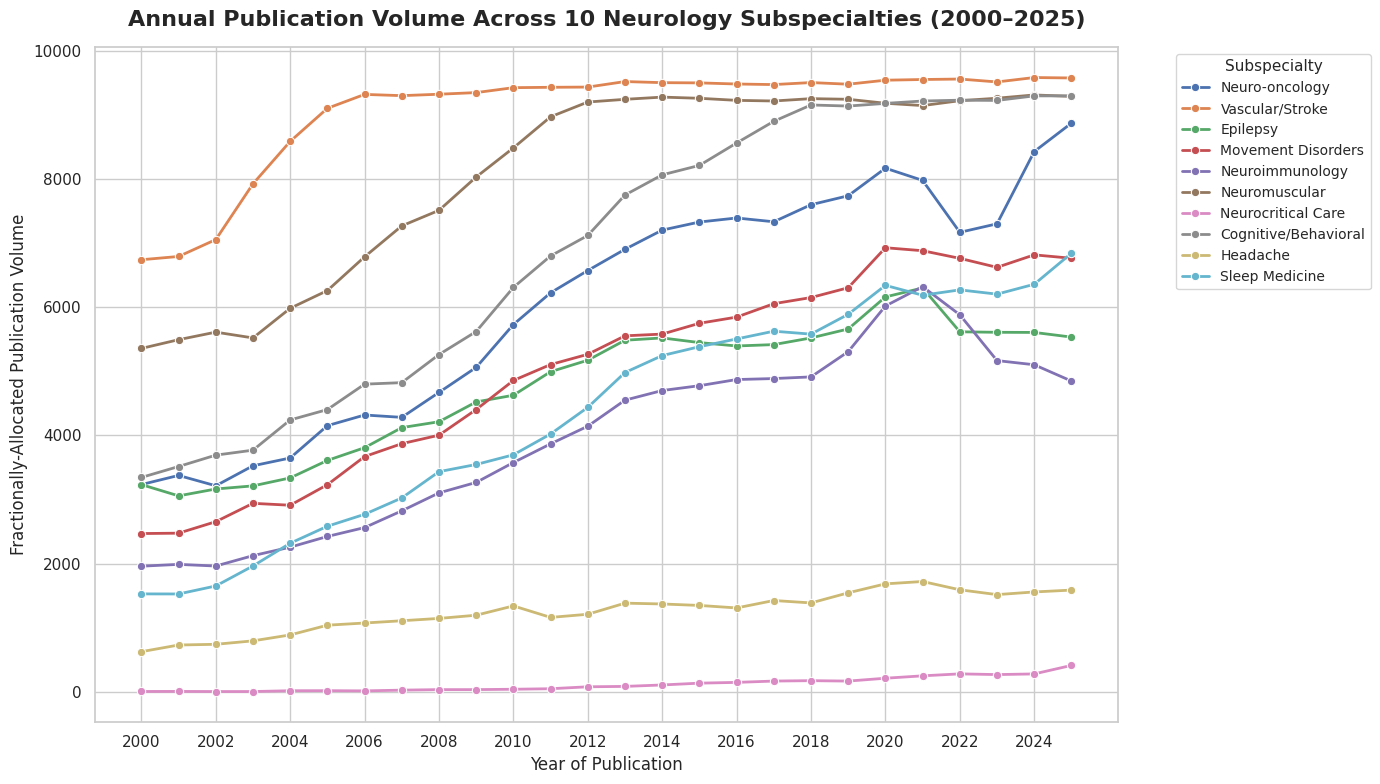

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 8))

# Plot a line for each subspecialty using the fractionally adjusted counts
sns.lineplot(
    data=df_fractional,
    x="Year",
    y="Fractional_Count",
    hue="Subspecialty",
    marker="o",
    linewidth=2
)

plt.title("Annual Publication Volume Across 10 Neurology Subspecialties (2000–2025)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Year of Publication", fontsize=12)
plt.ylabel("Fractionally-Allocated Publication Volume", fontsize=12)
plt.xticks(range(2000, 2026, 2))
plt.legend(title="Subspecialty", bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10, title_fontsize=11)
plt.tight_layout()

# Display the plot
plt.show()

In [24]:
import os, json, time, hashlib, warnings, contextlib, io
from collections import Counter
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)

START_YEAR, END_YEAR = 2000, 2024      # 2025 excluded: PubMed indexing & FY2025 awards incomplete
YEARS = list(range(START_YEAR, END_YEAR + 1))
DOLLAR_YEAR = 2024                     # money reported in constant FY2024 dollars (latest non-projected BRDPI)

NCBI_EMAIL   = "your.email@example.com"  # NCBI asks for a contact email
NCBI_API_KEY = None                      # optional free key (NCBI account settings): 3 -> 10 requests/s
NIH_FILTER   = ' AND "nih"[gr]'          # restricts PubMed to NIH-attributed papers

CACHE_DIR = "api_cache"   # Colab: use e.g. "/content/drive/MyDrive/lit_trends_cache" after mounting Drive
FIG_DIR   = "figures"
DATA_DIR  = "data_out"
SEER_CSV  = "seer_brain_5yr_survival.csv"  # two columns: Year, Survival_Pct (see Figure 5 notes)
for d in (CACHE_DIR, FIG_DIR, DATA_DIR):
    os.makedirs(d, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "axes.edgecolor": "#222222", "axes.linewidth": 0.8})

In [25]:
EUTILS   = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi"
REPORTER = "https://api.reporter.nih.gov/v2/projects/search"
CTGOV    = "https://clinicaltrials.gov/api/v2/studies"
_session = requests.Session()
_NCBI_PAUSE = 0.11 if NCBI_API_KEY else 0.34
_NIH_PAUSE  = 1.0   # RePORTER asks for no more than 1 request per second

def _cached(kind, key_obj, fetch):
    """Store each API answer on disk under a hash of its parameters, so interrupted runs resume."""
    key = hashlib.sha1(json.dumps(key_obj, sort_keys=True).encode()).hexdigest()
    path = os.path.join(CACHE_DIR, f"{kind}_{key}.json")
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    data = fetch()
    with open(path, "w") as f:
        json.dump(data, f)
    return data

def _request(method, url, pause, **kw):
    """HTTP request with retries. Raises after 5 failures instead of silently returning 0."""
    for attempt in range(5):
        try:
            r = _session.request(method, url, timeout=60, **kw)
            if r.status_code == 429 or r.status_code >= 500:
                raise requests.HTTPError(f"HTTP {r.status_code}")
            r.raise_for_status()
            data = r.json()
            time.sleep(pause)
            return data
        except (requests.RequestException, ValueError) as e:
            wait = 2 ** attempt
            print(f"  retry {attempt + 1}/5 after error: {e} (waiting {wait}s)")
            time.sleep(wait)
    raise RuntimeError(f"API failed after 5 attempts: {url}")

# ---------- PubMed ----------
def _esearch(term, mindate, maxdate, retmax):
    params = {"db": "pubmed", "term": term, "mindate": mindate, "maxdate": maxdate,
              "datetype": "pdat", "retmode": "json", "retmax": retmax, "email": NCBI_EMAIL}
    if NCBI_API_KEY:
        params["api_key"] = NCBI_API_KEY
    def fetch():
        res = _request("GET", EUTILS, _NCBI_PAUSE, params=params).get("esearchresult", {})
        if "ERROR" in res or "count" not in res:
            raise RuntimeError(f"PubMed rejected query: {term!r} -> {res}")
        return {"count": res["count"], "idlist": res.get("idlist", [])}
    return _cached("pubmed", [term, mindate, maxdate, retmax], fetch)

def pubmed_count(term, year):
    return int(_esearch(term, f"{year}/01/01", f"{year}/12/31", 0)["count"])

def pubmed_pmids(term, year):
    """All PMIDs for a query in one year. PubMed returns at most 9,999 IDs per search,
    so date ranges above that are split in half until each piece fits."""
    def fetch(start, end):
        res = _esearch(term, start.strftime("%Y/%m/%d"), end.strftime("%Y/%m/%d"), 9999)
        n = int(res["count"])
        if n <= 9999:
            return res["idlist"]
        if start >= end:
            print(f"  [!] {n} papers dated {start.date()} alone; only 9,999 retrievable")
            return res["idlist"]
        mid = (start + (end - start) / 2).normalize()
        return fetch(start, mid) + fetch(mid + pd.Timedelta(days=1), end)
    ids = list(dict.fromkeys(fetch(pd.Timestamp(year, 1, 1), pd.Timestamp(year, 12, 31))))
    expected = pubmed_count(term, year)
    if expected and abs(len(ids) - expected) / expected > 0.01:
        print(f"  [!] {year}: retrieved {len(ids)} PMIDs but PubMed reports {expected}")
    return ids

# ---------- NIH RePORTER ----------
def any_of(terms):
    return "(" + " OR ".join(f'"{t}"' for t in terms) + ")"

def nih_projects(search_text, year):
    """Every non-subproject NIH award matching the search in one fiscal year (all pages)."""
    def fetch():
        rows, offset, total = [], 0, 0
        while True:
            payload = {"criteria": {"fiscal_years": [year], "exclude_subprojects": True,
                                    "advanced_text_search": {"operator": "advanced",
                                                             "search_field": "projecttitle,terms",
                                                             "search_text": search_text}},
                       "include_fields": ["ApplId", "ProjectNum", "AwardAmount", "FiscalYear"],
                       "offset": offset, "limit": 500}
            data = _request("POST", REPORTER, _NIH_PAUSE, json=payload)
            total = data.get("meta", {}).get("total", 0)
            res = data.get("results", []) or []
            rows += [{"appl_id": p.get("appl_id"), "project_num": p.get("project_num"),
                      "award": p.get("award_amount") or 0} for p in res]
            offset += 500
            if not res or offset >= total:
                break
            if offset >= 15000:   # RePORTER cannot page past 15,000 records
                print(f"  [!] FY{year}: {total} matches; only the first 15,000 are retrievable. Narrow the query.")
                break
        return {"total": total, "rows": rows}
    out = _cached("nih", [search_text, year], fetch)
    df = pd.DataFrame(out["rows"], columns=["appl_id", "project_num", "award"])
    return df.drop_duplicates("appl_id")

# ---------- shared analysis helpers ----------
# NIH Biomedical Research and Development Price Index (FY1950 = 100).
# Source: NIH Office of Budget, "BRDPI Price Index Annual and Cumulative Values for 1950 through 2030"
# (FY2026 budget materials). FY2024 is preliminary; FY2025+ are projections and are not used.
BRDPI = {2000: 977.7, 2001: 1010.2, 2002: 1043.7, 2003: 1080.4, 2004: 1120.6, 2005: 1164.2,
         2006: 1218.1, 2007: 1264.4, 2008: 1323.5, 2009: 1362.3, 2010: 1403.7, 2011: 1443.9,
         2012: 1462.4, 2013: 1489.8, 2014: 1521.8, 2015: 1552.7, 2016: 1586.5, 2017: 1627.7,
         2018: 1668.3, 2019: 1703.6, 2020: 1733.4, 2021: 1776.7, 2022: 1858.2, 2023: 1929.5,
         2024: 1998.0}

def to_constant(nominal, year):
    """Convert nominal dollars in `year` to constant DOLLAR_YEAR dollars."""
    return nominal * BRDPI[DOLLAR_YEAR] / BRDPI[year]

def fractional_allocate(id_sets, values=None):
    """id_sets: {category: ids}. An item in k categories gives 1/k to each.
    With values ({id: dollars}) returns fractional dollars; otherwise fractional counts."""
    k = Counter(i for ids in id_sets.values() for i in set(ids))
    out = {}
    for cat, ids in id_sets.items():
        ids = set(ids)
        out[cat] = sum((values[i] if values is not None else 1.0) / k[i] for i in ids)
    return out

def lag_ccf(x, y, lags, detrend=True):
    """Correlate x(t) with y(t+k), both Series indexed by year. k > 0: x leads y.
    detrend=True correlates year-over-year changes instead of raw levels."""
    x, y = pd.Series(x, dtype=float), pd.Series(y, dtype=float)
    if detrend:
        x, y = x.diff(), y.diff()
    out = []
    for k in lags:
        pair = pd.concat([x, y.shift(-k)], axis=1).dropna()
        if len(pair) > 5 and pair.std().min() > 0:
            r, p = stats.pearsonr(pair.iloc[:, 0], pair.iloc[:, 1])
        else:
            r, p = np.nan, np.nan
        out.append({"Lag": k, "r": r, "p": p, "n": len(pair)})
    return pd.DataFrame(out)

def elasticity(funding, pubs, k):
    """Slope of dlog(pubs[t+k]) on dlog(funding[t]); 1.0 = papers grow in proportion to money."""
    f = np.log(pd.Series(funding, dtype=float).where(lambda s: s > 0)).diff()
    p = np.log(pd.Series(pubs, dtype=float).where(lambda s: s > 0)).diff().shift(-k)
    pair = pd.concat([f, p], axis=1).dropna()
    if len(pair) < 6:
        return np.nan, np.nan, np.nan
    fit = stats.linregress(pair.iloc[:, 0], pair.iloc[:, 1])
    return fit.slope, fit.slope - 1.96 * fit.stderr, fit.slope + 1.96 * fit.stderr

def stars(p):
    return "" if pd.isna(p) else "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

FLOW = []   # PRISMA-style data-flow records, printed at the end
def log_flow(source, step, n):
    FLOW.append({"Source": source, "Step": step, "Records": int(round(n))})

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=300, bbox_inches="tight")

# 1. Neurology Subspecialty Publication Landscape (PubMed)

This section counts papers per subspecialty per year, for all papers and for NIH-attributed papers. Papers that match several subspecialties are split fractionally between them. Large subspecialties exceed PubMed's 9,999-ID limit per search, so their years are split into smaller date ranges until every paper is retrieved.

In [26]:
BASE_QUERY = '"Neurology"[MeSH] OR "Nervous System Diseases"[MeSH]'

SUBSPECIALTIES = {
    "Neuro-oncology": '"Brain Neoplasms"[MeSH] OR "Central Nervous System Neoplasms"[MeSH] NOT (("Peripheral nerves"[tiab] AND "neoplasms"[MeSH]) OR "Neuroblastoma"[MeSH])',
    "Vascular/Stroke": '"Stroke"[MeSH] OR "Cerebrovascular Disorders"[MeSH] OR "Brain Ischemia"[MeSH] NOT ("Heat Stroke"[MeSH] OR heatstroke[tiab] OR "myocardial infarction"[tiab])',
    "Epilepsy": '"Epilepsy"[MeSH] OR "Seizures"[MeSH] OR "Status Epilepticus"[MeSH] NOT ("Eclampsia"[MeSH] OR "non-epileptic"[tiab] OR "psychogenic"[tiab])',
    "Movement Disorders": '"Movement Disorders"[MeSH] OR "Parkinson Disease"[MeSH] OR "Huntington Disease"[MeSH] NOT ("Bowel movement"[tiab] OR "Eye Movements"[MeSH])',
    "Neuroimmunology": '"Multiple Sclerosis"[MeSH] OR "Autoimmune Diseases of the Nervous System"[MeSH] OR "Encephalomyelitis"[MeSH] NOT "Systemic Lupus Erythematosus"[MeSH:NoExp]',
    "Neuromuscular": '"Neuromuscular Diseases"[MeSH] OR "Motor Neuron Disease"[MeSH] OR "Peripheral Nervous System Diseases"[MeSH] NOT "Neuromuscular Blockade"[MeSH]',
    "Neurocritical Care": '"Neurocritical care"[tiab] OR (("Brain Injuries, Traumatic"[MeSH] OR "Coma"[MeSH]) AND "Intensive Care"[MeSH]) NOT "neonatal intensive care"[tiab]',
    "Cognitive/Behavioral": '"Dementia"[MeSH] OR "Alzheimer Disease"[MeSH] OR "Frontotemporal Lobar Degeneration"[MeSH] NOT ("Schizophrenia"[MeSH] OR "Intellectual Disability"[MeSH])',
    "Headache": '"Headache Disorders"[MeSH] OR "Migraine Disorders"[MeSH] NOT ("dental"[tiab] OR "Sinusitis"[MeSH] OR "Post-Dural Puncture Headache"[MeSH])',
    "Sleep Medicine": '"Sleep Wake Disorders"[MeSH] OR "Narcolepsy"[MeSH] NOT "Anesthesia"[MeSH]',
}

rows, n_ident, n_unique, n_ident_nih, n_unique_nih = [], 0, 0, 0, 0
print("Extracting subspecialty publications (PubMed)...")
for year in YEARS:
    total_all = pubmed_count(BASE_QUERY, year)
    total_nih = pubmed_count(f"({BASE_QUERY}){NIH_FILTER}", year)
    ids_all = {s: pubmed_pmids(f"({q})", year) for s, q in SUBSPECIALTIES.items()}
    ids_nih = {s: pubmed_pmids(f"({q}){NIH_FILTER}", year) for s, q in SUBSPECIALTIES.items()}
    frac_all, frac_nih = fractional_allocate(ids_all), fractional_allocate(ids_nih)
    n_ident += sum(map(len, ids_all.values()));      n_unique += len(set().union(*ids_all.values()))
    n_ident_nih += sum(map(len, ids_nih.values()));  n_unique_nih += len(set().union(*ids_nih.values()))
    for s in SUBSPECIALTIES:
        rows.append({"Year": year, "Subspecialty": s,
                     "Raw_Count": len(ids_all[s]), "Fractional_Count": frac_all[s],
                     "NIH_Raw_Count": len(ids_nih[s]), "NIH_Fractional_Count": frac_nih[s],
                     "Total_Neurology": total_all, "Total_Neurology_NIH": total_nih})
    print(f"  {year} done")

df_pubs = pd.DataFrame(rows)
df_pubs.to_csv(os.path.join(DATA_DIR, "subspecialty_publications.csv"), index=False)
log_flow("PubMed: subspecialties (all)", "Subspecialty matches identified", n_ident)
log_flow("PubMed: subspecialties (all)", "Unique papers after cross-subspecialty deduplication", n_unique)
log_flow("PubMed: subspecialties (NIH)", "Subspecialty matches identified", n_ident_nih)
log_flow("PubMed: subspecialties (NIH)", "Unique papers after cross-subspecialty deduplication", n_unique_nih)
display(df_pubs.head(10))

Extracting subspecialty publications (PubMed)...
  2000 done
  2001 done
  2002 done
  2003 done
  2004 done
  2005 done
  2006 done
  2007 done
  2008 done
  2009 done
  2010 done
  2011 done
  2012 done
  2013 done
  2014 done
  2015 done
  2016 done
  2017 done
  2018 done
  2019 done
  2020 done
  2021 done
  2022 done
  2023 done
  2024 done


,Year,Subspecialty,Raw_Count,Fractional_Count,NIH_Raw_Count,NIH_Fractional_Count,Total_Neurology,Total_Neurology_NIH
0,2000,Neuro-oncology,3411,3233.250000,272,263.000000,48563,4440
1,2000,Vascular/Stroke,7289,6741.250000,554,520.500000,48563,4440
2,2000,Epilepsy,3450,3232.616667,303,290.833333,48563,4440
3,2000,Movement Disorders,2851,2468.700000,315,262.000000,48563,4440
4,2000,Neuroimmunology,2485,1959.366667,212,185.833333,48563,4440
5,2000,Neuromuscular,5912,5357.416667,346,315.333333,48563,4440
6,2000,Neurocritical Care,7,4.500000,0,0.000000,48563,4440
7,2000,Cognitive/Behavioral,3814,3344.283333,662,598.166667,48563,4440
8,2000,Headache,668,625.416667,17,16.000000,48563,4440
9,2000,Sleep Medicine,1613,1527.200000,158,153.333333,48563,4440


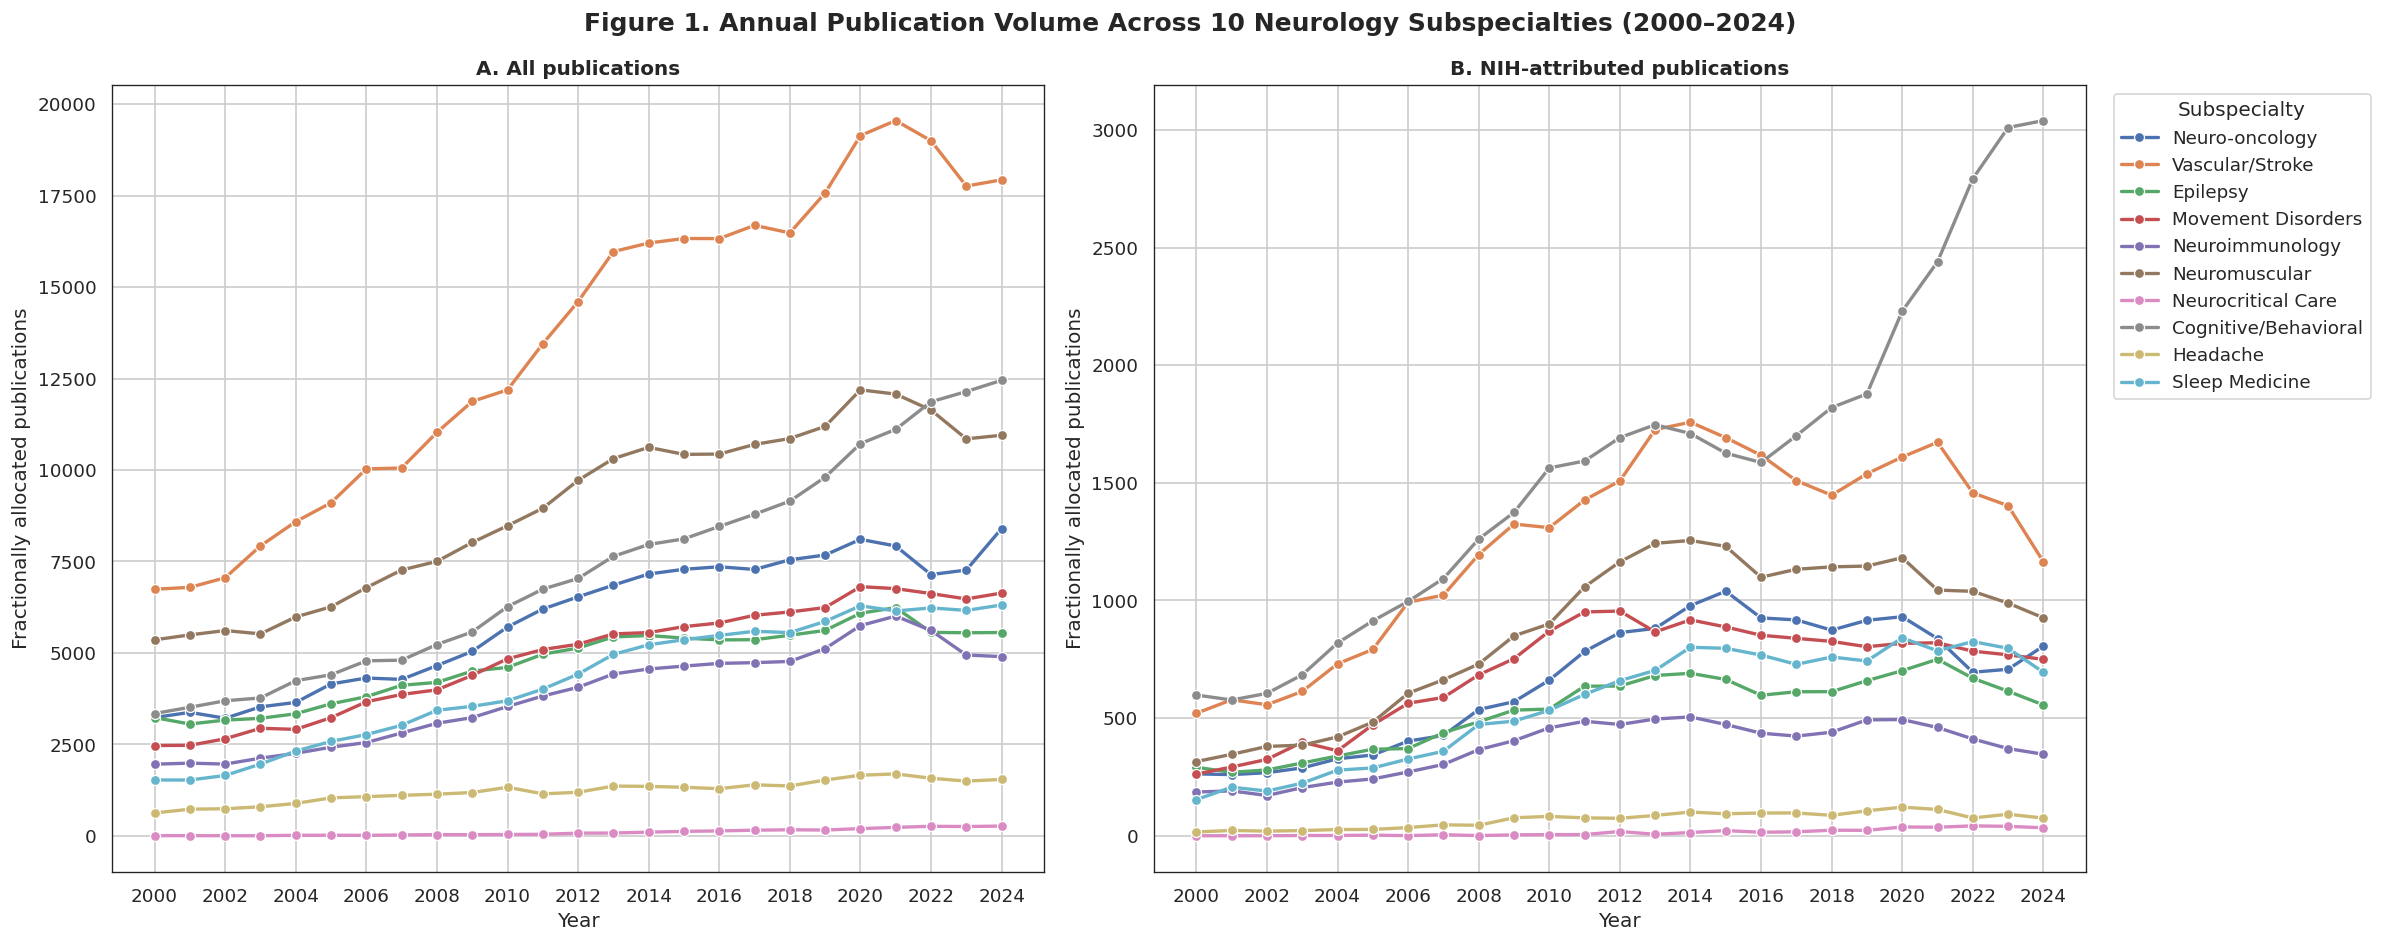

In [27]:
# Figure 1: publication volume by subspecialty
fig, axes = plt.subplots(1, 2, figsize=(20, 8), dpi=120)
for ax, col, title in [(axes[0], "Fractional_Count", "A. All publications"),
                       (axes[1], "NIH_Fractional_Count", "B. NIH-attributed publications")]:
    sns.lineplot(data=df_pubs, x="Year", y=col, hue="Subspecialty", marker="o", linewidth=2, ax=ax,
                 legend=(ax is axes[1]))
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Fractionally allocated publications")
    ax.set_xticks(range(START_YEAR, END_YEAR + 1, 2))
axes[1].legend(title="Subspecialty", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle(f"Figure 1. Annual Publication Volume Across 10 Neurology Subspecialties ({START_YEAR}–{END_YEAR})",
             fontsize=15, fontweight="bold")
fig.tight_layout()
save(fig, "fig1_subspecialty_publications")
plt.show()

#Figure 1: Raw Annual Publication Volume Across 10 Neurology Subspecialties 2000-2024 with NIH Attribution
- **A.** Each line is one area of neurology, showing how many research papers it published each year; a rising line means that field is publishing more.
- **B.** The same picture, counting only papers that credit NIH funding, which is the fair thing to compare against NIH dollars later on.





---



### Growth models

**Annual growth IRR** comes from a quasi-Poisson GLM with log(total neurology papers) as an offset. An IRR above 1 means the subspecialty grew faster than neurology overall. For example, 1.03 means about 3% faster per year.

**Breakpoint** is the year where a two-segment straight line fits best. The two slopes show papers per year added before and after that year. This step is exploratory; it does not formally test whether a break exists.

In [11]:
import statsmodels.api as sm

def best_breakpoint(t, y, min_seg=4):
    """Single-break piecewise linear fit chosen by minimum residual sum of squares."""
    best = None
    for b in t[min_seg:-min_seg]:
        X = np.column_stack([np.ones_like(t), t, np.maximum(0, t - b)])
        coef, res, *_ = np.linalg.lstsq(X, y, rcond=None)
        sse = float(np.sum((y - X @ coef) ** 2))
        if best is None or sse < best[0]:
            best = (sse, b, coef)
    _, b, coef = best
    return int(b), coef[1], coef[1] + coef[2]

growth = []
for s, g in df_pubs.groupby("Subspecialty"):
    g = g.sort_values("Year")
    t = (g["Year"] - START_YEAR).to_numpy(float)
    y = g["Fractional_Count"].to_numpy(float)
    X = sm.add_constant(t)
    fit = sm.GLM(np.round(y), X, family=sm.families.Poisson(),
                 offset=np.log(g["Total_Neurology"].to_numpy(float))).fit(scale="X2")
    ci = np.exp(np.asarray(fit.conf_int())[1])
    b, slope_pre, slope_post = best_breakpoint(t, y)
    growth.append({"Subspecialty": s,
                   "Papers_first_year": y[0], "Papers_last_year": y[-1],
                   "Growth_IRR_vs_neurology": np.exp(np.asarray(fit.params)[1]),
                   "IRR_95CI": f"{ci[0]:.3f}–{ci[1]:.3f}",
                   "p": np.asarray(fit.pvalues)[1],
                   "Breakpoint_year": START_YEAR + b,
                   "Slope_before (papers/yr)": slope_pre, "Slope_after (papers/yr)": slope_post})
df_growth = pd.DataFrame(growth).sort_values("Growth_IRR_vs_neurology", ascending=False)
df_growth.to_csv(os.path.join(DATA_DIR, "subspecialty_growth_models.csv"), index=False)
display(df_growth.round(3))

,Subspecialty,Papers_first_year,Papers_last_year,Growth_IRR_vs_neurology,IRR_95CI,p,Breakpoint_year,Slope_before (papers/yr),Slope_after (papers/yr)
5,Neurocritical Care,4.500,267.833,1.125,1.112–1.138,0.000,2010,3.251,17.142
0,Cognitive/Behavioral,3344.283,12451.767,1.020,1.016–1.024,0.000,2008,237.872,451.493
8,Sleep Medicine,1527.200,6310.250,1.019,1.015–1.022,0.000,2016,269.398,107.264
6,Neuroimmunology,1959.367,4899.233,1.008,1.006–1.011,0.000,2020,199.182,-132.998
9,Vascular/Stroke,6741.250,17931.483,1.005,1.004–1.007,0.000,2020,646.920,-274.493
3,Movement Disorders,2468.700,6636.683,1.004,1.003–1.005,0.000,2014,251.007,115.168
4,Neuro-oncology,3233.250,8399.500,1.002,0.999–1.004,0.196,2015,305.435,72.994
7,Neuromuscular,5357.417,10949.317,0.996,0.995–0.998,0.000,2020,360.411,-301.932
2,Headache,625.417,1542.033,0.993,0.989–0.997,0.001,2007,71.472,29.334
1,Epilepsy,3232.617,5557.900,0.989,0.988–0.990,0.000,2014,187.315,35.698


# 2. NIH Funding Across Neurology Subspecialties (NIH RePORTER)

**Primary method: NIH's official RCDC spending categories.** NIH assigns every grant to standardized Research, Condition, and Disease Categories (RCDC) using a uniform algorithm, and RePORTER can filter on them directly. These are the numbers NIH itself reports to Congress, so they avoid the noise of keyword matching. RCDC began in FY2008, so this comparison covers FY2008–FY2024.

**Sensitivity check: keyword search, 2000–2024.** The earlier keyword method is kept and run alongside. For FY2008 onward, the notebook prints how closely the two methods agree for each subspecialty.

**Category ID check.** The category ID numbers come from NIH's RePORTER API documentation (Appendix I). On every run, the notebook checks that the grants returned are actually labeled with the expected category names, and prints a warning if an ID looks wrong.

**About Cognitive/Behavioral.** Alzheimer's disease and related dementias have received dedicated congressional appropriations since the National Alzheimer's Project Act (2011). That makes this field far larger than the others. It is kept in every analysis and named as an outlier, but share comparisons are also shown without it so it does not flatten the other nine fields.

In [28]:
NIH_SUBSPECIALTY_SEARCH = {
    "Neuro-oncology": any_of(["neuro-oncology", "glioblastoma", "glioma", "medulloblastoma",
                              "ependymoma", "brain tumor", "brain neoplasm"]),
    "Vascular/Stroke": any_of(["stroke", "cerebrovascular", "cerebral ischemia", "intracerebral hemorrhage",
                               "subarachnoid hemorrhage", "intracranial aneurysm"]),
    "Epilepsy": any_of(["epilepsy", "epileptic", "seizure", "status epilepticus"]),
    "Movement Disorders": any_of(["Parkinson", "Huntington", "dystonia", "essential tremor", "movement disorder"]),
    "Neuroimmunology": any_of(["multiple sclerosis", "neuromyelitis optica", "autoimmune encephalitis",
                               "encephalomyelitis"]),
    "Neuromuscular": any_of(["amyotrophic lateral sclerosis", "motor neuron disease", "muscular dystrophy",
                             "myasthenia gravis", "peripheral neuropathy", "spinal muscular atrophy"]),
    "Neurocritical Care": '("neurocritical care" OR "neurointensive" OR "coma" OR '
                          '("traumatic brain injury" AND ("intensive care" OR "ICU")))',
    "Cognitive/Behavioral": any_of(["Alzheimer", "dementia", "frontotemporal"]),
    "Headache": any_of(["migraine", "headache"]),
    "Sleep Medicine": any_of(["sleep disorder", "insomnia", "narcolepsy", "sleep apnea"]),
}

rows, n_ident, n_unique = [], 0, 0
print("Extracting NIH funding by subspecialty (RePORTER, ~1 request/s)...")
for year in YEARS:
    proj = {s: nih_projects(q, year) for s, q in NIH_SUBSPECIALTY_SEARCH.items()}
    amounts = {}
    for p in proj.values():
        amounts.update(dict(zip(p["appl_id"], p["award"])))
    frac = fractional_allocate({s: p["appl_id"].tolist() for s, p in proj.items()}, values=amounts)
    n_ident += sum(len(p) for p in proj.values()); n_unique += len(amounts)
    for s, p in proj.items():
        rows.append({"Year": year, "Subspecialty": s, "Grants": len(p),
                     "Funding_Nominal_M": p["award"].sum() / 1e6,
                     "Funding_Frac_Nominal_M": frac[s] / 1e6,
                     "Funding_Frac_Const_M": to_constant(frac[s], year) / 1e6})
    print(f"  FY{year} done")

df_fund_sub = pd.DataFrame(rows)
df_fund_sub.to_csv(os.path.join(DATA_DIR, "subspecialty_nih_funding.csv"), index=False)
log_flow("NIH RePORTER: subspecialties", "Award matches identified", n_ident)
log_flow("NIH RePORTER: subspecialties", "Unique awards after cross-subspecialty deduplication", n_unique)
display(df_fund_sub[df_fund_sub["Year"] == END_YEAR].round(1))

Extracting NIH funding by subspecialty (RePORTER, ~1 request/s)...
  FY2000 done
  FY2001 done
  FY2002 done
  FY2003 done
  FY2004 done
  FY2005 done
  FY2006 done
  FY2007 done
  FY2008 done
  FY2009 done
  FY2010 done
  FY2011 done
  FY2012 done
  FY2013 done
  FY2014 done
  FY2015 done
  FY2016 done
  FY2017 done
  FY2018 done
  FY2019 done
  FY2020 done
  FY2021 done
  FY2022 done
  FY2023 done
  FY2024 done


,Year,Subspecialty,Grants,Funding_Nominal_M,Funding_Frac_Nominal_M,Funding_Frac_Const_M
240,2024,Neuro-oncology,1129,625.9,588.2,588.2
241,2024,Vascular/Stroke,3846,2379.6,1740.1,1740.1
242,2024,Epilepsy,1244,617.9,423.3,423.3
243,2024,Movement Disorders,1759,997.7,593.6,593.6
244,2024,Neuroimmunology,775,434.9,329.3,329.3
245,2024,Neuromuscular,1283,861.1,567.4,567.4
246,2024,Neurocritical Care,184,116.9,91.0,91.0
247,2024,Cognitive/Behavioral,7039,4994.8,4048.4,4048.4
248,2024,Headache,297,158.7,119.1,119.1
249,2024,Sleep Medicine,573,290.2,221.2,221.2


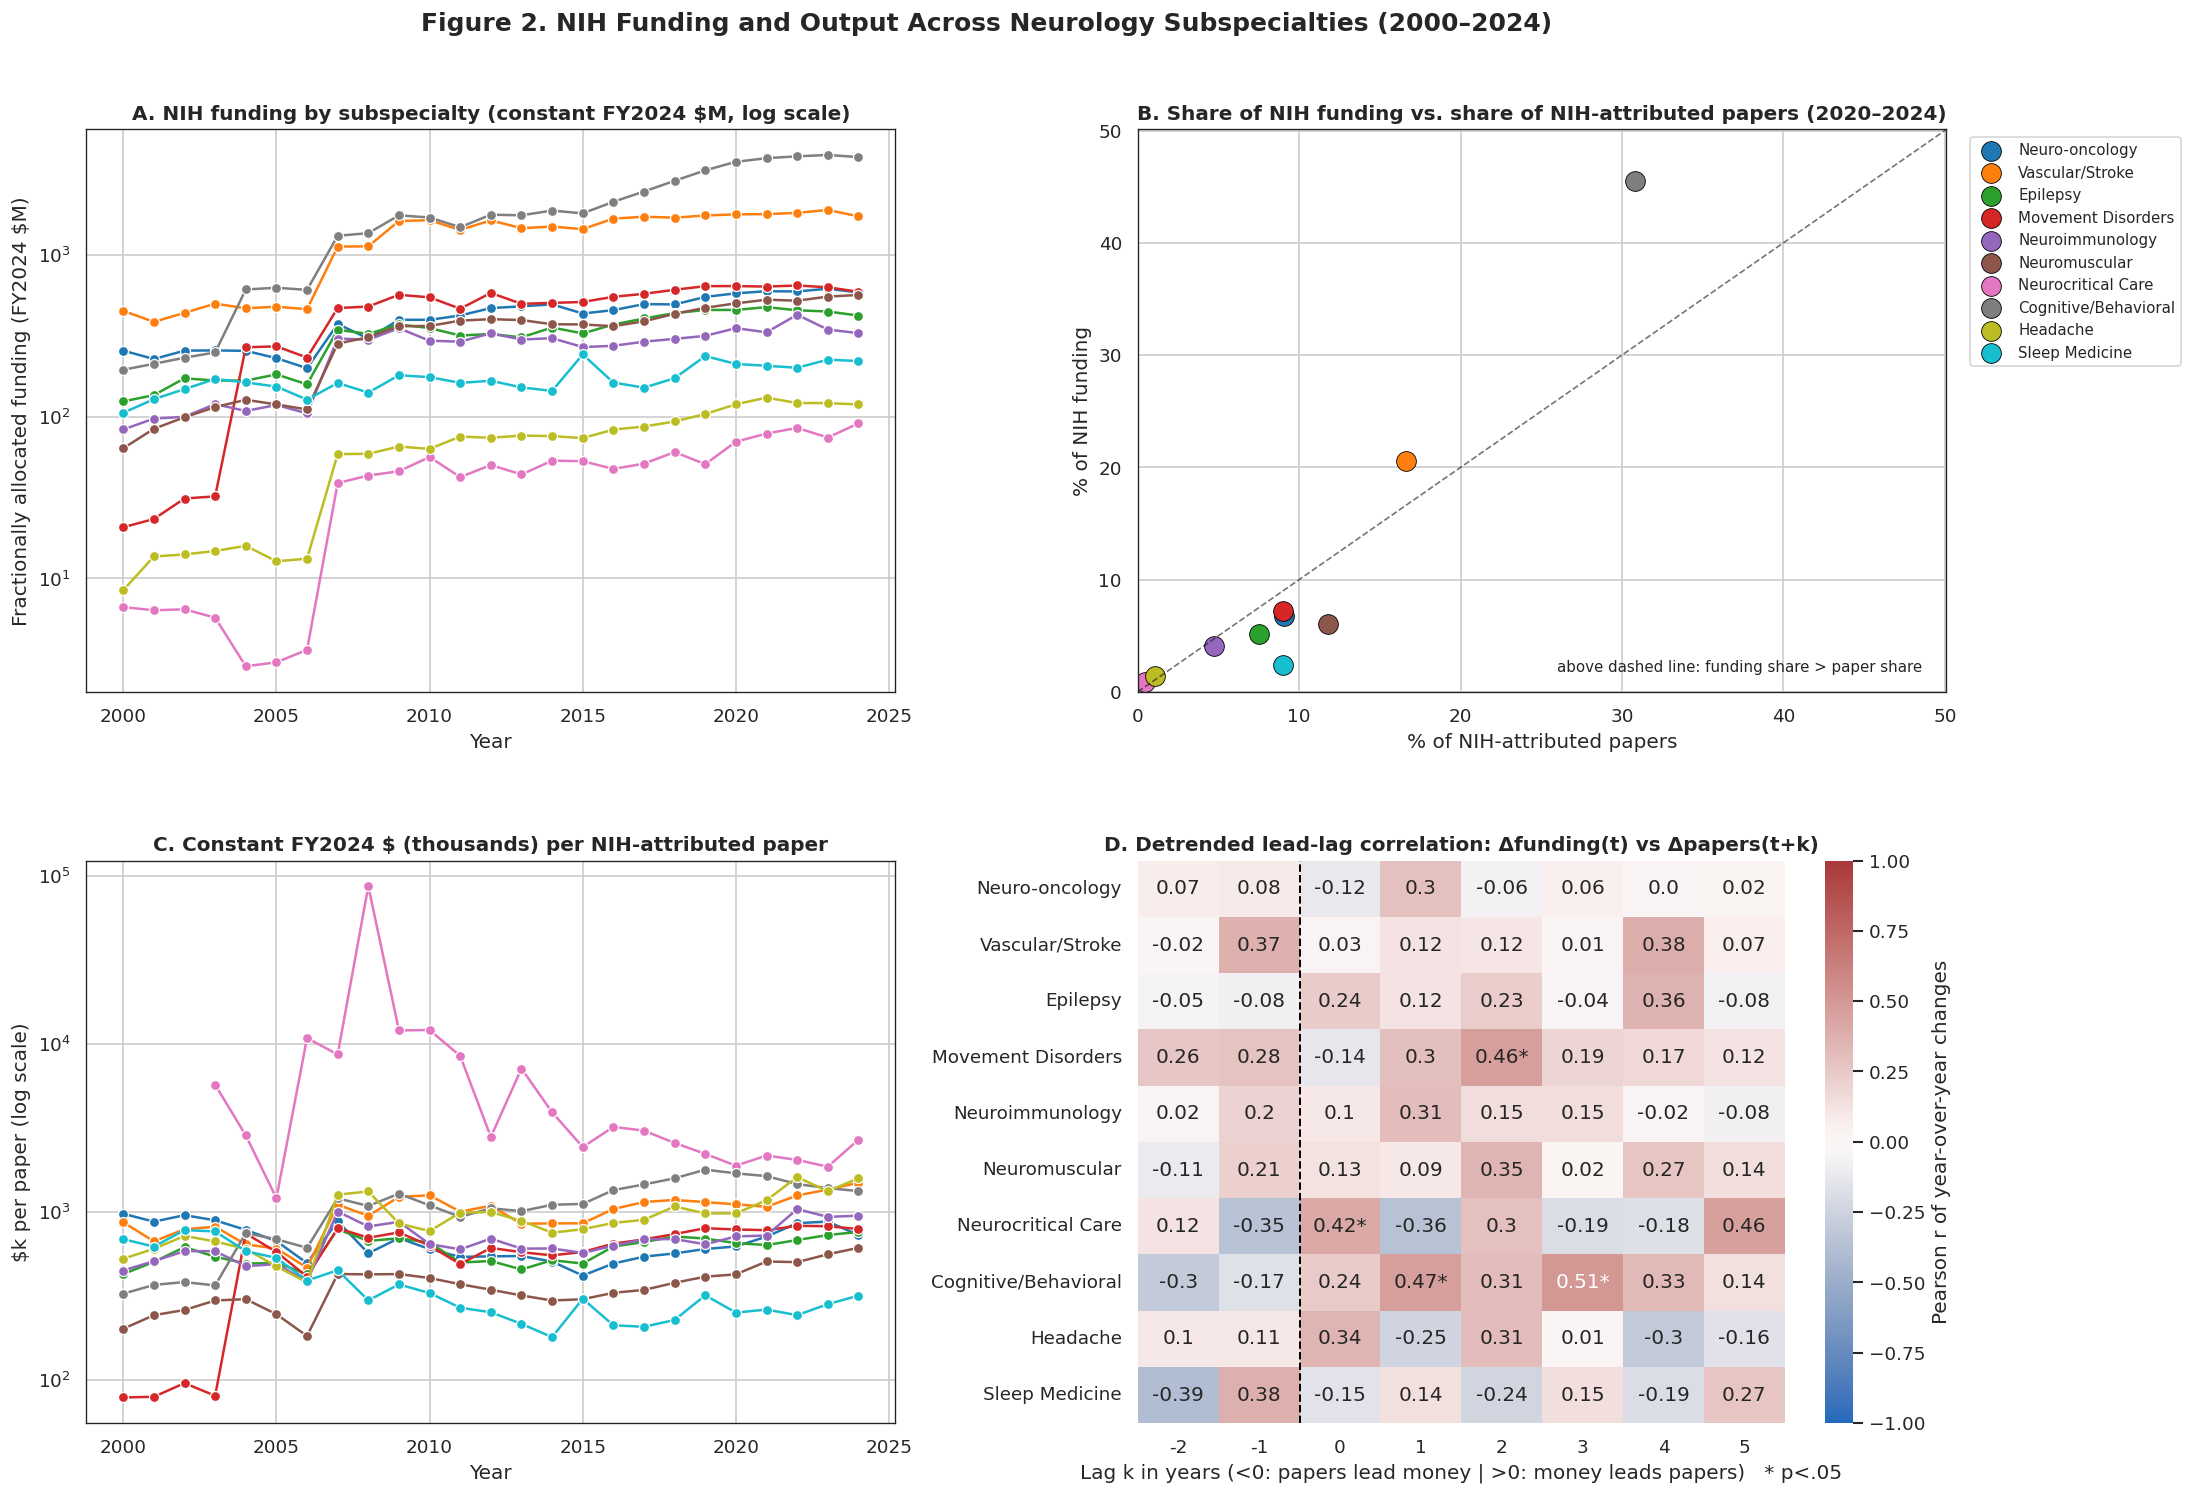

,% funding,% NIH papers
Subspecialty,,
Cognitive/Behavioral,45.5,30.8
Epilepsy,5.1,7.5
Headache,1.4,1.1
Movement Disorders,7.2,9.0
Neuro-oncology,6.8,9.1
Neurocritical Care,0.9,0.4
Neuroimmunology,4.1,4.7
Neuromuscular,6.1,11.8
Sleep Medicine,2.4,9.0


In [29]:
# Figure 2: funding vs. output across subspecialties
sub = df_fund_sub.merge(df_pubs[["Year", "Subspecialty", "NIH_Fractional_Count"]], on=["Year", "Subspecialty"])
sub["Const_k_per_NIH_paper"] = 1e3 * sub["Funding_Frac_Const_M"] / sub["NIH_Fractional_Count"].replace(0, np.nan)
order = list(SUBSPECIALTIES)
palette = dict(zip(order, sns.color_palette("tab10", len(order))))

fig, axes = plt.subplots(2, 2, figsize=(20, 14), dpi=120)
plt.subplots_adjust(hspace=0.3, wspace=0.3)

ax = axes[0, 0]
sns.lineplot(data=sub, x="Year", y="Funding_Frac_Const_M", hue="Subspecialty", hue_order=order,
             palette=palette, marker="o", ax=ax, legend=False)
ax.set_yscale("log")
ax.set_title(f"A. NIH funding by subspecialty (constant FY{DOLLAR_YEAR} $M, log scale)", fontweight="bold")
ax.set_ylabel(f"Fractionally allocated funding (FY{DOLLAR_YEAR} $M)")

ax = axes[0, 1]
recent = sub[sub["Year"] >= END_YEAR - 4].groupby("Subspecialty")[["Funding_Frac_Const_M", "NIH_Fractional_Count"]].sum()
share = 100 * recent / recent.sum()
for s in order:
    if s in share.index:
        r = share.loc[s]
        ax.scatter(r["NIH_Fractional_Count"], r["Funding_Frac_Const_M"], s=140, color=palette[s],
                   label=s, edgecolor="black", linewidth=0.5)
lim = max(share.max()) * 1.1
ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.6)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title(f"B. Share of NIH funding vs. share of NIH-attributed papers ({END_YEAR-4}–{END_YEAR})", fontweight="bold")
ax.set_xlabel("% of NIH-attributed papers"); ax.set_ylabel("% of NIH funding")
ax.text(0.97, 0.03, "above dashed line: funding share > paper share", transform=ax.transAxes,
        fontsize=9, ha="right", va="bottom")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)

ax = axes[1, 0]
sns.lineplot(data=sub, x="Year", y="Const_k_per_NIH_paper", hue="Subspecialty", hue_order=order,
             palette=palette, marker="o", ax=ax, legend=False)
ax.set_yscale("log")
ax.set_title(f"C. Constant FY{DOLLAR_YEAR} $ (thousands) per NIH-attributed paper", fontweight="bold")
ax.set_ylabel("$k per paper (log scale)")

ax = axes[1, 1]
lags = list(range(-2, 6))
ccf_sub = {}
for s in order:
    g = sub[sub["Subspecialty"] == s].set_index("Year").sort_index()
    ccf_sub[s] = lag_ccf(g["Funding_Frac_Const_M"], g["NIH_Fractional_Count"], lags).set_index("Lag")
r_mat = pd.DataFrame({s: c["r"] for s, c in ccf_sub.items()}).T
p_mat = pd.DataFrame({s: c["p"] for s, c in ccf_sub.items()}).T
annot = r_mat.round(2).astype(str) + p_mat.map(stars)
sns.heatmap(r_mat, annot=annot, fmt="", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Pearson r of year-over-year changes"})
ax.axvline(x=lags.index(0), color="black", ls="--", lw=1.2)
ax.set_title("D. Detrended lead-lag correlation: Δfunding(t) vs Δpapers(t+k)", fontweight="bold")
ax.set_xlabel("Lag k in years (<0: papers lead money | >0: money leads papers)   * p<.05")

fig.suptitle(f"Figure 2. NIH Funding and Output Across Neurology Subspecialties ({START_YEAR}–{END_YEAR})",
             fontsize=15, fontweight="bold", y=0.95)
save(fig, "fig2_subspecialty_funding")
plt.show()
r_mat.to_csv(os.path.join(DATA_DIR, "subspecialty_lag_r.csv")); p_mat.to_csv(os.path.join(DATA_DIR, "subspecialty_lag_p.csv"))
display((share.rename(columns={"Funding_Frac_Const_M": "% funding", "NIH_Fractional_Count": "% NIH papers"})).round(1))

#Figure 2: NIH Funding and Output Across Neurology Subspecialties
- **A.** Each line shows how much inflation-adjusted NIH money a field received each year. The scale is logarithmic, so equal steps up mean equal percentage growth. The thick dashed line (Alzheimer's/dementia) sits far above the rest because Congress sets aside dedicated money for it.
- **B.** Every field is reset to 100 in 2008, so you can see whose budget grew fastest regardless of starting size; a line at 200 means that field's money doubled.
- **C.** Each dot is a field: above the dashed diagonal means it gets a bigger slice of NIH money than its slice of NIH-funded papers. Dementia is left out so its size doesn't squash everyone else.
- **D.** Each box asks whether a jump in a field's funding is followed by a jump in its papers *k* years later: red means yes, blue means the opposite, near-white means no link, and a star means the pattern is unlikely to be chance.



---



# 3. Neuro-Oncology: NIH Funding vs. Publication Output

This section uses the same neuro-oncology search as the original analysis, now paged and inflation-adjusted. Publications are counted two ways: all papers, and NIH-attributed papers. NIH-attributed papers are the fair comparison for NIH dollars.

In [14]:
NO_SEARCH = NIH_SUBSPECIALTY_SEARCH["Neuro-oncology"]
NO_PUBMED = '("Brain Neoplasms"[MeSH Terms] OR "Glioblastoma"[MeSH Terms] OR "neuro-oncology"[Title/Abstract] OR "glioma"[Title/Abstract])'

rows = []
print("Extracting neuro-oncology funding and publications...")
for y in YEARS:
    proj = nih_projects(NO_SEARCH, y)
    nominal = proj["award"].sum()
    rows.append({"Year": y, "Grants": len(proj),
                 "Funding_Nominal_M": nominal / 1e6,
                 "Funding_Const_M": to_constant(nominal, y) / 1e6,
                 "Pubs_All": pubmed_count(NO_PUBMED, y),
                 "Pubs_NIH": pubmed_count(NO_PUBMED + NIH_FILTER, y)})
df_no = pd.DataFrame(rows).set_index("Year")
df_no.to_csv(os.path.join(DATA_DIR, "neuro_oncology_funding_pubs.csv"))
log_flow("NIH RePORTER: neuro-oncology", "Unique awards (summed over years)", df_no["Grants"].sum())
log_flow("PubMed: neuro-oncology", "Papers, all (summed over years)", df_no["Pubs_All"].sum())
log_flow("PubMed: neuro-oncology", "Papers, NIH-attributed (summed over years)", df_no["Pubs_NIH"].sum())

# Sanity check against the original (paged) first run, nominal $M
ORIGINAL_RUN = {2000: 126.50, 2007: 245.72, 2016: 386.12, 2024: 625.87}
print("\nNominal funding, this run vs original paged run ($M):")
for y, v in ORIGINAL_RUN.items():
    if y in df_no.index:
        print(f"  FY{y}: {df_no.loc[y, 'Funding_Nominal_M']:8.1f}  vs  {v:8.1f}")
print("(Large gaps mean RePORTER is reading the search string differently; check the operator.)")
display(df_no.round(1))

Extracting neuro-oncology funding and publications...

Nominal funding, this run vs original paged run ($M):
  FY2000:    126.5  vs     126.5
  FY2007:    245.7  vs     245.7
  FY2016:    386.1  vs     386.1
  FY2024:    625.9  vs     625.9
(Large gaps mean RePORTER is reading the search string differently; check the operator.)


,Grants,Funding_Nominal_M,Funding_Const_M,Pubs_All,Pubs_NIH
Year,,,,,
2000,288,126.5,258.5,3278,363
2001,291,116.2,229.8,3346,363
2002,330,135.2,258.9,3246,343
2003,340,140.8,260.3,3501,386
2004,339,145.2,258.9,3679,417
2005,325,136.1,233.6,4056,478
2006,299,122.9,201.5,4347,562
2007,535,245.7,388.3,4298,562
2008,587,213.5,322.3,4792,693


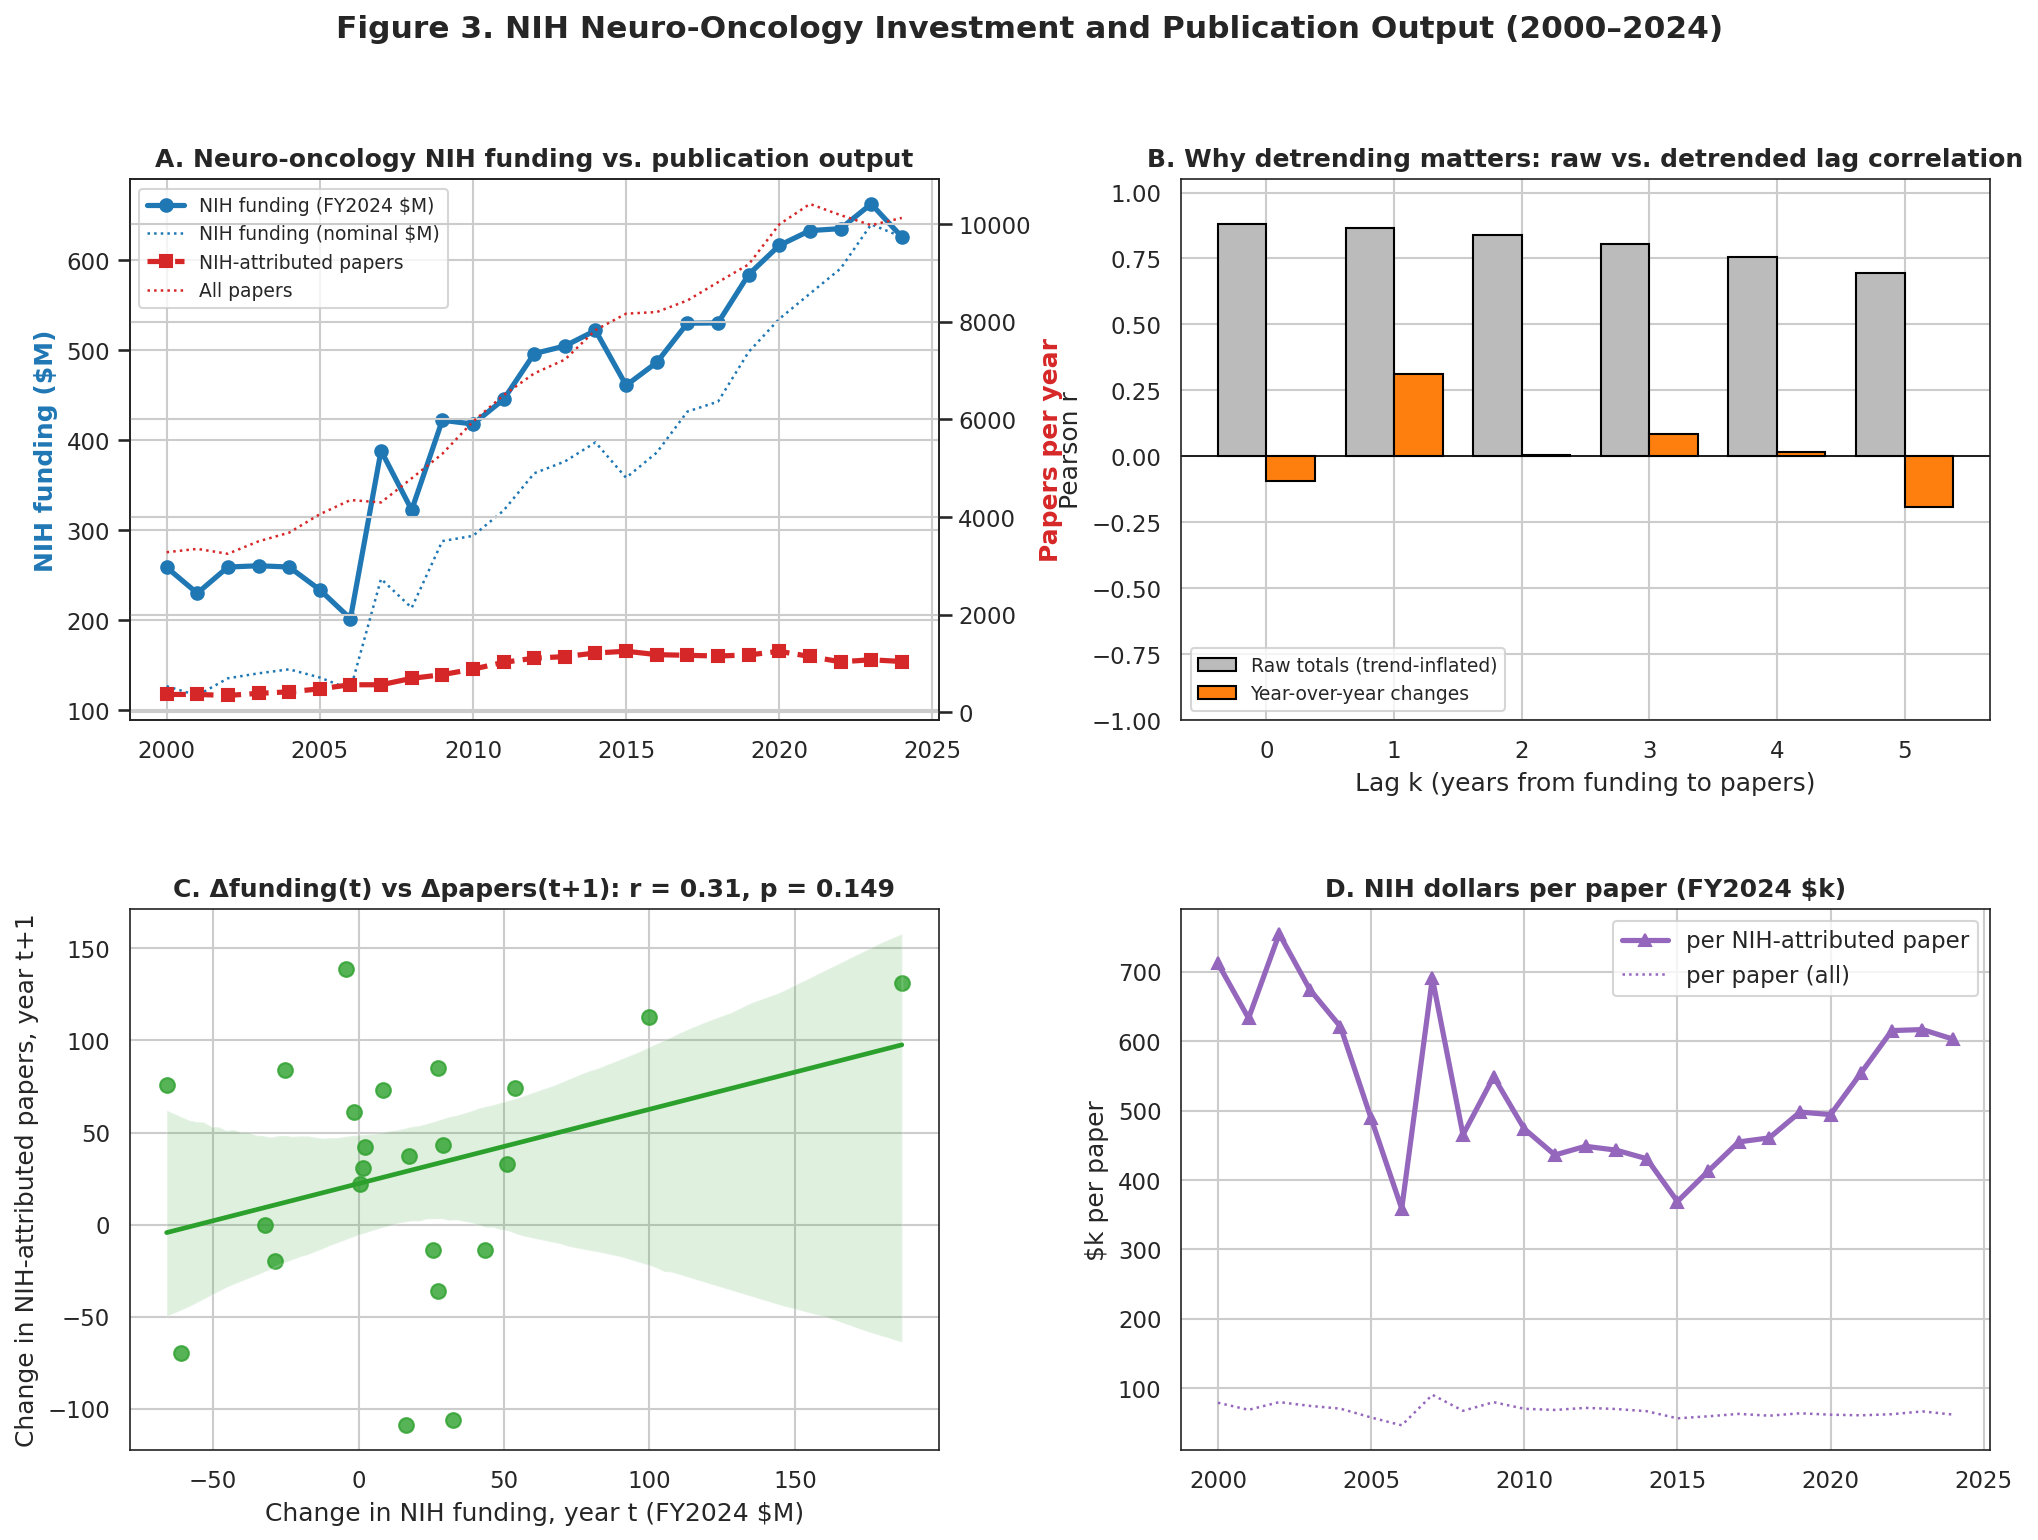

raw            detrended           
         r      p   n         r      p   n
Lag                                       
0    0.882  0.000  25    -0.094  0.661  24
1    0.867  0.000  24     0.311  0.149  23
2    0.839  0.000  23     0.005  0.983  22
3    0.804  0.000  22     0.084  0.718  21
4    0.756  0.000  21     0.016  0.946  20
5    0.693  0.001  20    -0.192  0.432  19

In [15]:
# Figure 3: neuro-oncology funding vs papers
lags = list(range(0, 6))
ccf_raw = lag_ccf(df_no["Funding_Const_M"], df_no["Pubs_NIH"], lags, detrend=False)
ccf_det = lag_ccf(df_no["Funding_Const_M"], df_no["Pubs_NIH"], lags, detrend=True)
best_lag_no = int(ccf_det.loc[ccf_det["r"].idxmax(), "Lag"])

fig, axes = plt.subplots(2, 2, figsize=(16, 11), dpi=150)
plt.subplots_adjust(hspace=0.35, wspace=0.3)

ax1 = axes[0, 0]; ax2 = ax1.twinx()
ax1.plot(df_no.index, df_no["Funding_Const_M"], color="#1f77b4", lw=2.5, marker="o", label=f"NIH funding (FY{DOLLAR_YEAR} $M)")
ax1.plot(df_no.index, df_no["Funding_Nominal_M"], color="#1f77b4", lw=1.2, ls=":", label="NIH funding (nominal $M)")
ax2.plot(df_no.index, df_no["Pubs_NIH"], color="#d62728", lw=2.5, marker="s", ls="--", label="NIH-attributed papers")
ax2.plot(df_no.index, df_no["Pubs_All"], color="#d62728", lw=1.2, ls=":", label="All papers")
ax1.set_ylabel("NIH funding ($M)", color="#1f77b4", fontweight="bold")
ax2.set_ylabel("Papers per year", color="#d62728", fontweight="bold")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
ax1.set_title("A. Neuro-oncology NIH funding vs. publication output", fontweight="bold")

ax = axes[0, 1]
w = 0.38
ax.bar(np.array(lags) - w/2, ccf_raw["r"], w, color="#bbbbbb", edgecolor="black", label="Raw totals (trend-inflated)")
ax.bar(np.array(lags) + w/2, ccf_det["r"], w, color="#ff7f0e", edgecolor="black", label="Year-over-year changes")
for _, r in ccf_det.iterrows():
    ax.text(r["Lag"] + w/2, (r["r"] if r["r"] > 0 else 0) + 0.03, stars(r["p"]), ha="center")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylim(-1, 1.05)
ax.set_title("B. Why detrending matters: raw vs. detrended lag correlation", fontweight="bold")
ax.set_xlabel("Lag k (years from funding to papers)"); ax.set_ylabel("Pearson r")
ax.legend(loc="lower left", fontsize=9)

ax = axes[1, 0]
d = pd.DataFrame({"dF": df_no["Funding_Const_M"].diff(), "dP": df_no["Pubs_NIH"].diff().shift(-best_lag_no)}).dropna()
sns.regplot(data=d, x="dF", y="dP", ax=ax, color="#2ca02c", scatter_kws={"s": 50})
rb = ccf_det.set_index("Lag").loc[best_lag_no]
ax.set_title(f"C. Δfunding(t) vs Δpapers(t+{best_lag_no}): r = {rb['r']:.2f}, p = {rb['p']:.3f}", fontweight="bold")
ax.set_xlabel(f"Change in NIH funding, year t (FY{DOLLAR_YEAR} $M)")
ax.set_ylabel(f"Change in NIH-attributed papers, year t+{best_lag_no}")

ax = axes[1, 1]
ax.plot(df_no.index, 1e3 * df_no["Funding_Const_M"] / df_no["Pubs_NIH"], color="#9467bd", lw=2.5, marker="^",
        label="per NIH-attributed paper")
ax.plot(df_no.index, 1e3 * df_no["Funding_Const_M"] / df_no["Pubs_All"], color="#9467bd", lw=1.2, ls=":",
        label="per paper (all)")
ax.set_title(f"D. NIH dollars per paper (FY{DOLLAR_YEAR} $k)", fontweight="bold")
ax.set_ylabel("$k per paper"); ax.legend()

fig.suptitle(f"Figure 3. NIH Neuro-Oncology Investment and Publication Output ({START_YEAR}–{END_YEAR})",
             fontsize=15, fontweight="bold", y=0.98)
save(fig, "fig3_neuro_oncology_funding_pubs")
plt.show()
display(pd.concat({"raw": ccf_raw.set_index("Lag"), "detrended": ccf_det.set_index("Lag")}, axis=1).round(3))

#Figure 3: NIH Neuro-Oncology Investment and Publication Output
- **A.** Brain-tumor NIH money (blue) and brain-tumor papers (red) each year. Solid lines are inflation-adjusted dollars and NIH-funded papers; dotted lines are unadjusted dollars and all papers.
- **B.** Gray bars show how linked money and papers *look* when you compare raw totals, which is misleadingly high because both simply grow over time; orange bars compare year-to-year changes instead, which is the honest test.
- **C.** Each dot is a year; if extra money in one year tends to come with extra papers a year or more later, the dots slope upward.
- **D.** How many inflation-adjusted NIH dollars go into each published brain-tumor paper; a rising line means papers are getting more expensive to produce.



---



### Granger causality (both directions)

The test runs on year-over-year changes of inflation-adjusted funding and NIH-attributed papers. It is run in both directions, because money can follow promising science as well as produce it. The Augmented Dickey–Fuller (ADF) test checks that the differenced series are stationary, which Granger testing assumes. p-values are Holm-corrected across the four lags tested in each direction.

In [16]:
from statsmodels.tsa.stattools import grangercausalitytests, adfuller
from statsmodels.stats.multitest import multipletests

d = df_no[["Funding_Const_M", "Pubs_NIH"]].diff().dropna()
for col in d:
    print(f"ADF stationarity on Δ{col}: p = {adfuller(d[col].values)[1]:.3f} (p < .05 suggests stationary)")

def granger_table(target, predictor, maxlag=4):
    with contextlib.redirect_stdout(io.StringIO()):   # silence statsmodels' verbose printout
        res = grangercausalitytests(d[[target, predictor]].values, maxlag=maxlag)
    p_raw = [res[k][0]["ssr_ftest"][1] for k in range(1, maxlag + 1)]
    p_holm = multipletests(p_raw, method="holm")[1]
    return pd.DataFrame({"Lag": range(1, maxlag + 1), "F": [res[k][0]["ssr_ftest"][0] for k in range(1, maxlag + 1)],
                         "p_raw": p_raw, "p_Holm": p_holm})

granger_f2p = granger_table("Pubs_NIH", "Funding_Const_M")
granger_p2f = granger_table("Funding_Const_M", "Pubs_NIH")
print("\nFunding → papers (H0: past funding changes do not predict paper changes)")
display(granger_f2p.round(4))
print("Papers → funding (H0: past paper changes do not predict funding changes)")
display(granger_p2f.round(4))

eps, lo, hi = elasticity(df_no["Funding_Const_M"], df_no["Pubs_NIH"], best_lag_no)
print(f"\nFunding elasticity at lag +{best_lag_no}: ε = {eps:.2f} (95% CI {lo:.2f} to {hi:.2f})")
print("ε = 1 means papers grow in proportion to funding; ε < 1 means each extra dollar buys fewer papers.")

ADF stationarity on ΔFunding_Const_M: p = 0.000 (p < .05 suggests stationary)
ADF stationarity on ΔPubs_NIH: p = 0.907 (p < .05 suggests stationary)

Funding → papers (H0: past funding changes do not predict paper changes)


,Lag,F,p_raw,p_Holm
0,1,3.8109,0.0651,0.2602
1,2,1.3800,0.2784,0.6852
2,3,1.5736,0.2401,0.6852
3,4,1.6609,0.2284,0.6852


Papers → funding (H0: past paper changes do not predict funding changes)


,Lag,F,p_raw,p_Holm
0,1,0.3815,0.5438,1.0
1,2,0.3378,0.7180,1.0
2,3,0.1761,0.9108,1.0
3,4,0.3445,0.8424,1.0



Funding elasticity at lag +1: ε = 0.21 (95% CI 0.01 to 0.40)
ε = 1 means papers grow in proportion to funding; ε < 1 means each extra dollar buys fewer papers.


# 4. Neuro-Oncology Methodological Paradigms

This section splits neuro-oncology grants and NIH-attributed papers into the five paradigms. A grant or paper matching several paradigms is split fractionally between them, so the shares add to 100% of classified work without double-counting.

Coverage is also reported: the fraction of neuro-oncology dollars that fall into any paradigm. If coverage is low, the shares describe only the classified portion of the field.

In [17]:
MODALITIES = {
    "1. Surgery & Local Control": {
        "nih_terms": ["neurosurgery", "resection", "craniotomy", "laser interstitial", "convection enhanced"],
        "pubmed_query": '("neurosurgery"[Title/Abstract] OR "resection"[Title/Abstract] OR "craniotomy"[Title/Abstract] OR "LITT"[Title/Abstract])',
        "color": "#4E79A7"},
    "2. Radiation & Biophysical": {
        "nih_terms": ["radiotherapy", "radiation therapy", "radiosurgery", "proton therapy", "tumor treating fields"],
        "pubmed_query": '("radiotherapy"[Title/Abstract] OR "radiosurgery"[Title/Abstract] OR "proton therapy"[Title/Abstract] OR "tumor treating fields"[Title/Abstract])',
        "color": "#F28E2B"},
    "3. Cytotoxic Chemotherapy": {
        "nih_terms": ["temozolomide", "lomustine", "carmustine", "nitrosourea", "alkylating"],
        "pubmed_query": '("temozolomide"[Title/Abstract] OR "lomustine"[Title/Abstract] OR "carmustine"[Title/Abstract] OR "alkylating"[Title/Abstract])',
        "color": "#E15759"},
    "4. Molecular & Genetic": {
        "nih_terms": ["IDH1", "MGMT", "EGFR", "genomic", "epigenetic", "sequencing", "CRISPR", "mutation"],
        "pubmed_query": '("IDH1"[Title/Abstract] OR "MGMT"[Title/Abstract] OR "EGFR"[Title/Abstract] OR "genomics"[Title/Abstract] OR "sequencing"[Title/Abstract] OR "epigenetic"[Title/Abstract])',
        "color": "#76B7B2"},
    "5. Immunotherapy & Viral": {
        "nih_terms": ["immunotherapy", "CAR-T", "checkpoint inhibitor", "oncolytic virus", "dendritic cell", "T cell"],
        "pubmed_query": '("immunotherapy"[Title/Abstract] OR "CAR-T"[Title/Abstract] OR "checkpoint"[Title/Abstract] OR "oncolytic"[Title/Abstract] OR "vaccine"[Title/Abstract])',
        "color": "#59A14F"},
}
BASE_TUMOR_TERMS = ["glioblastoma", "glioma", "brain tumor", "brain neoplasm", "neuro-oncology", "medulloblastoma"]
BASE_TUMOR_PUBMED = '("Brain Neoplasms"[MeSH Terms] OR "Glioblastoma"[MeSH Terms] OR "glioma"[Title/Abstract])'
MOD_NAMES = list(MODALITIES)

rows, coverage = [], []
n_g_ident = n_g_unique = n_p_ident = n_p_unique = 0
print("Extracting paradigm-level funding and publications...")
for y in YEARS:
    base = nih_projects(any_of(BASE_TUMOR_TERMS), y)
    proj = {m: nih_projects(f"{any_of(BASE_TUMOR_TERMS)} AND {any_of(c['nih_terms'])}", y) for m, c in MODALITIES.items()}
    pmids = {m: pubmed_pmids(f"{BASE_TUMOR_PUBMED} AND {c['pubmed_query']}{NIH_FILTER}", y) for m, c in MODALITIES.items()}
    amounts = {}
    for p in proj.values():
        amounts.update(dict(zip(p["appl_id"], p["award"])))
    f_frac = fractional_allocate({m: p["appl_id"].tolist() for m, p in proj.items()}, values=amounts)
    p_frac = fractional_allocate(pmids)
    n_g_ident += sum(len(p) for p in proj.values()); n_g_unique += len(amounts)
    n_p_ident += sum(map(len, pmids.values()));      n_p_unique += len(set().union(*pmids.values()))
    base_dollars = base["award"].sum()
    coverage.append({"Year": y, "Coverage_%": 100 * sum(amounts.values()) / base_dollars if base_dollars else np.nan})
    row = {"Year": y}
    for m in MOD_NAMES:
        row[f"{m}_Funding"] = to_constant(f_frac[m], y) / 1e6
        row[f"{m}_Pubs"] = p_frac[m]
    rows.append(row)
    print(f"  FY{y} done")

df_mod = pd.DataFrame(rows).set_index("Year")
f_cols = [f"{m}_Funding" for m in MOD_NAMES]; p_cols = [f"{m}_Pubs" for m in MOD_NAMES]
df_mod["Total_Funding"] = df_mod[f_cols].sum(axis=1)
df_mod["Total_Pubs"] = df_mod[p_cols].sum(axis=1)
df_mod.to_csv(os.path.join(DATA_DIR, "paradigm_funding_pubs.csv"))
df_cov = pd.DataFrame(coverage).set_index("Year")
log_flow("NIH RePORTER: paradigms", "Paradigm matches identified", n_g_ident)
log_flow("NIH RePORTER: paradigms", "Unique awards after cross-paradigm deduplication", n_g_unique)
log_flow("PubMed: paradigms (NIH)", "Paradigm matches identified", n_p_ident)
log_flow("PubMed: paradigms (NIH)", "Unique papers after cross-paradigm deduplication", n_p_unique)
print(f"\nShare of neuro-oncology dollars classified into any paradigm: "
      f"median {df_cov['Coverage_%'].median():.0f}% (range {df_cov['Coverage_%'].min():.0f}–{df_cov['Coverage_%'].max():.0f}%)")

Extracting paradigm-level funding and publications...
  FY2000 done
  FY2001 done
  FY2002 done
  FY2003 done
  FY2004 done
  FY2005 done
  FY2006 done
  FY2007 done
  FY2008 done
  FY2009 done
  FY2010 done
  FY2011 done
  FY2012 done
  FY2013 done
  FY2014 done
  FY2015 done
  FY2016 done
  FY2017 done
  FY2018 done
  FY2019 done
  FY2020 done
  FY2021 done
  FY2022 done
  FY2023 done
  FY2024 done

Share of neuro-oncology dollars classified into any paradigm: median 69% (range 38–88%)


Computed optimal lag (detrended, total classified neuro-oncology): +5 years


,Lag,r,p,n
0,-2,0.061,0.788,22
1,-1,0.081,0.715,23
2,0,0.005,0.982,24
3,1,0.291,0.179,23
4,2,-0.104,0.646,22
5,3,0.111,0.632,21
6,4,-0.323,0.165,20
7,5,0.351,0.141,19


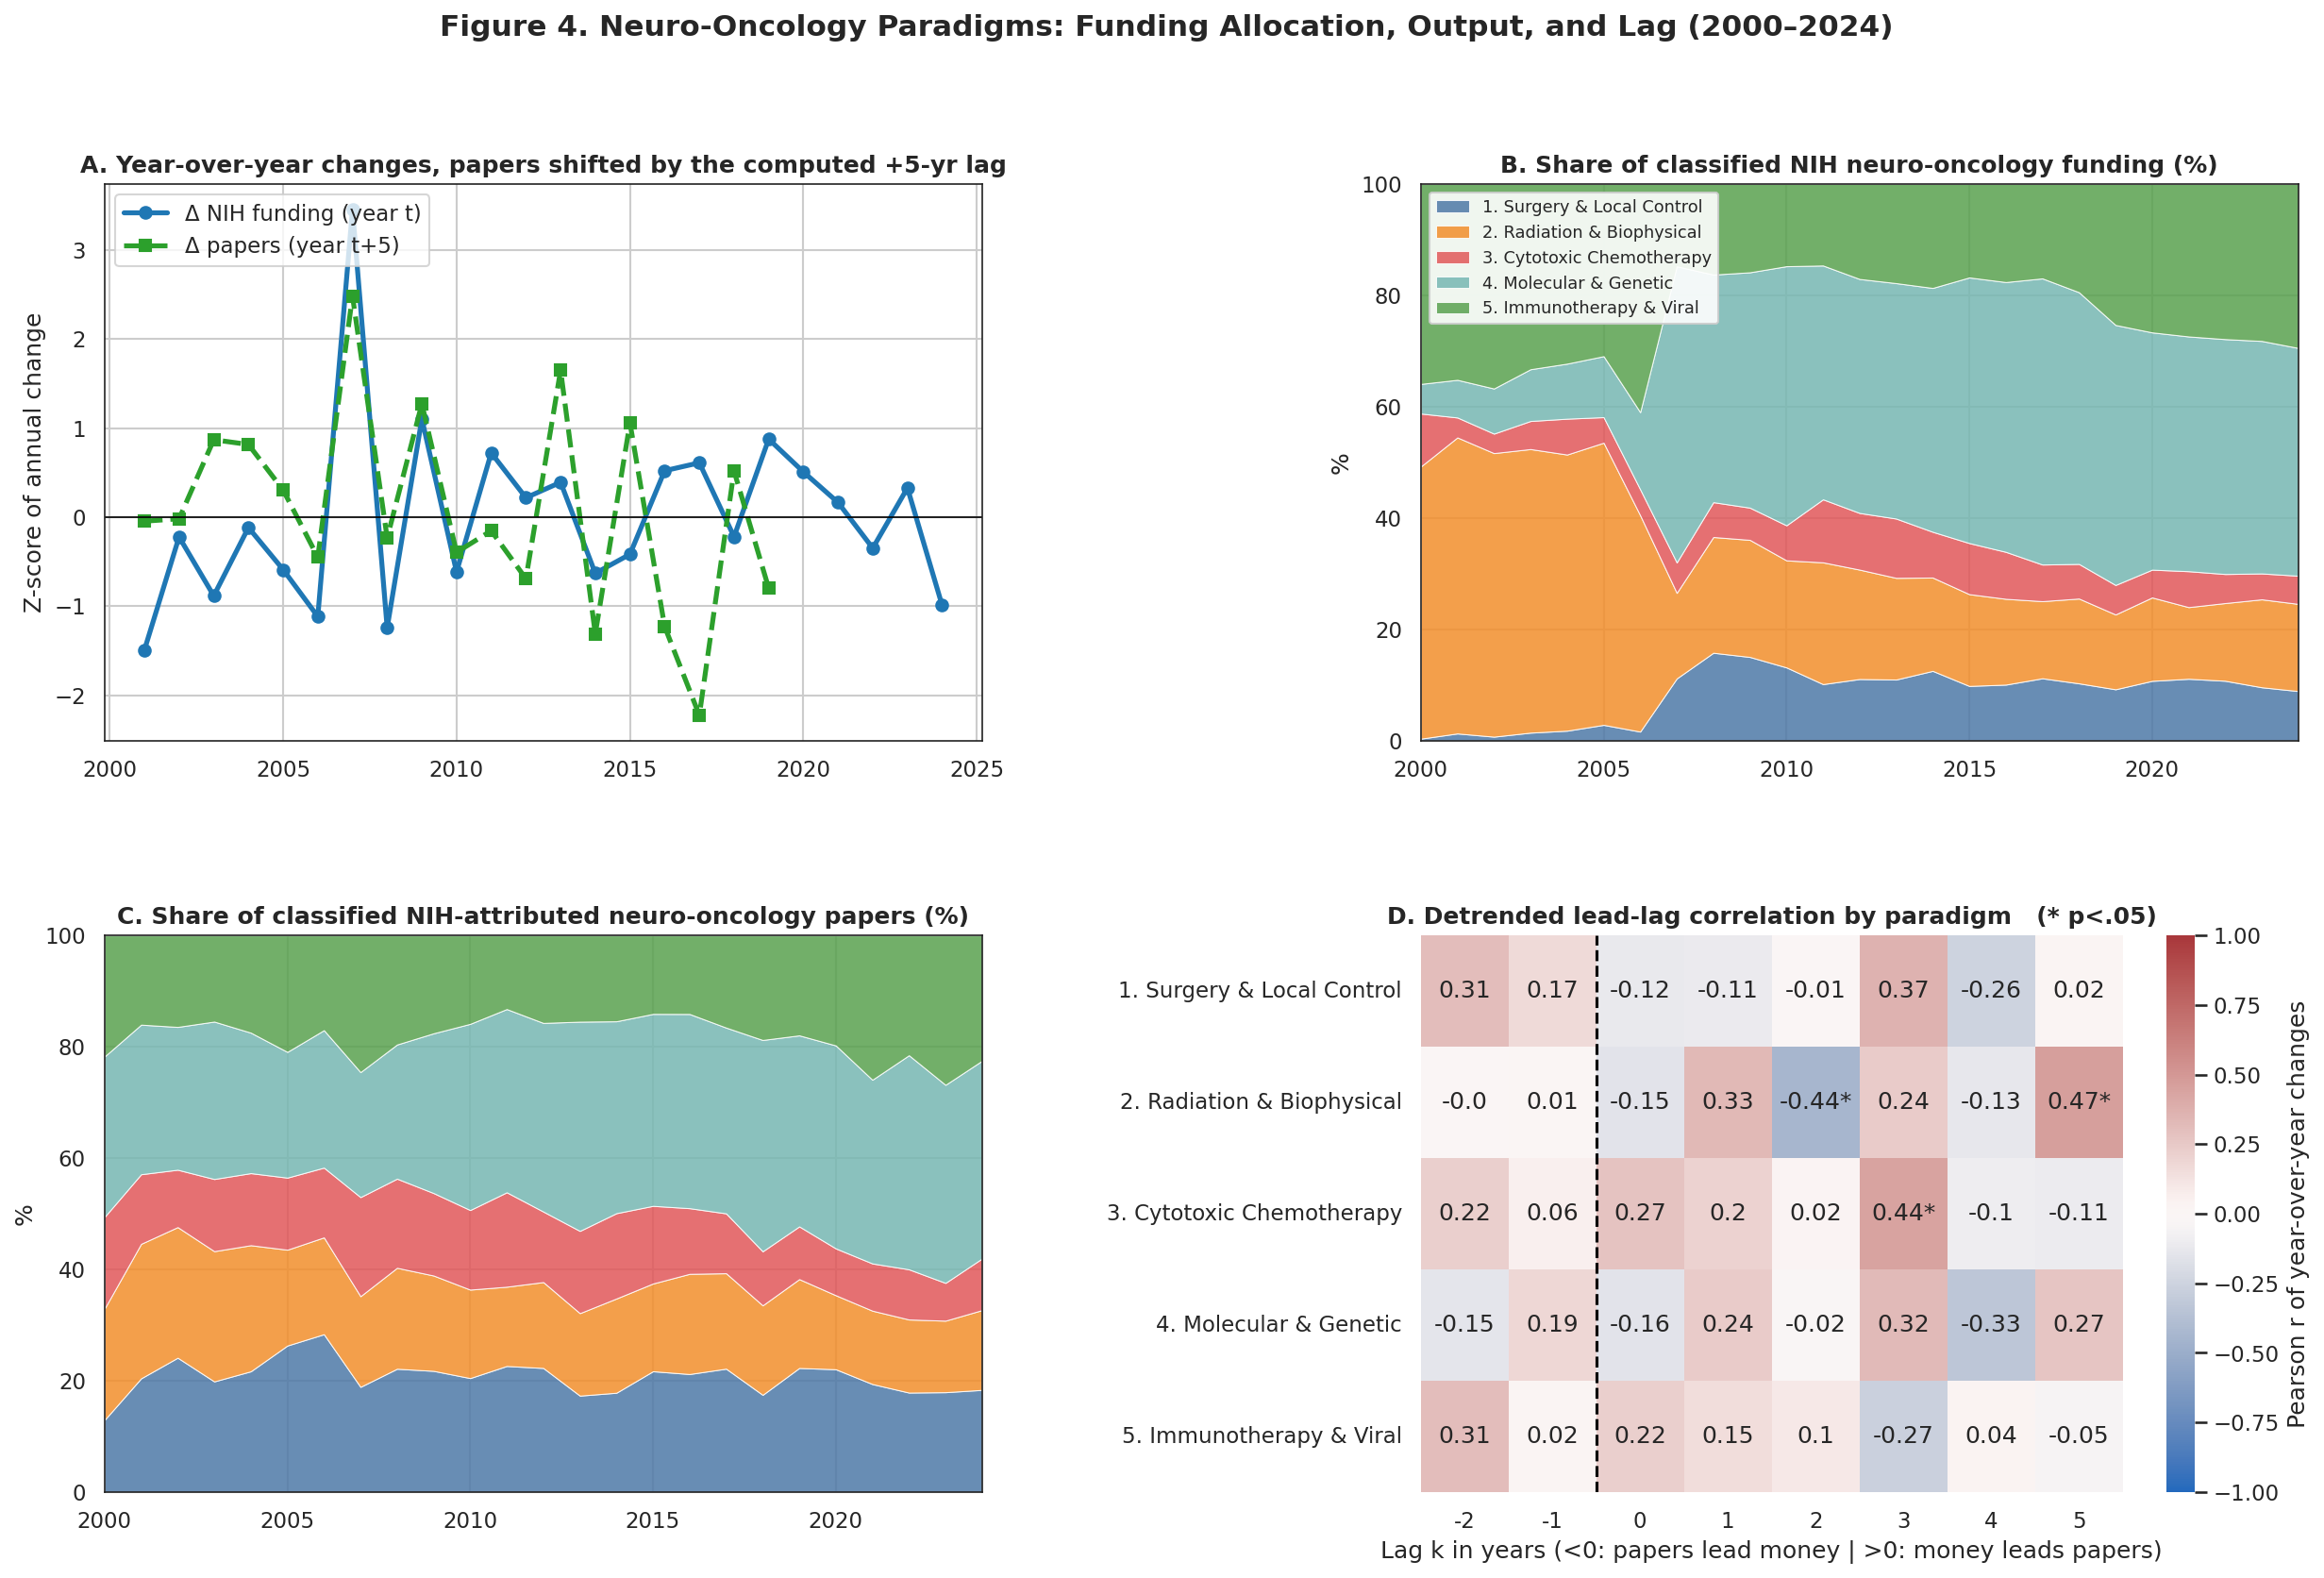

,% funding 2020–2024,% papers 2020–2024,% funding 2000–2004,Elasticity ε (lag +5),ε 95% CI,Peak detrended lag,Peak r,Peak p
1. Surgery & Local Control,10.19,19.20,1.02,0.10,-0.00 to 0.20,3,0.37,0.10
2. Radiation & Biophysical,14.67,13.36,50.59,0.29,-0.03 to 0.62,5,0.47,0.04
3. Cytotoxic Chemotherapy,5.27,8.38,5.90,-0.03,-0.19 to 0.12,3,0.44,0.05
4. Molecular & Genetic,41.93,35.76,7.62,0.10,-0.03 to 0.22,3,0.32,0.15
5. Immunotherapy & Viral,27.94,23.31,34.88,0.28,-0.25 to 0.82,-2,0.31,0.17


In [18]:
# Lag is computed from the data (it was hard-coded to 3 in the original)
lags = list(range(-2, 6))
ccf_tot = lag_ccf(df_mod["Total_Funding"], df_mod["Total_Pubs"], lags)
pos = ccf_tot[ccf_tot["Lag"] >= 0]
OPT_LAG = int(pos.loc[pos["r"].idxmax(), "Lag"])
print(f"Computed optimal lag (detrended, total classified neuro-oncology): +{OPT_LAG} years")
display(ccf_tot.round(3))

ccf_mod = {m: lag_ccf(df_mod[f"{m}_Funding"], df_mod[f"{m}_Pubs"], lags).set_index("Lag") for m in MOD_NAMES}
r_mod = pd.DataFrame({m: c["r"] for m, c in ccf_mod.items()}).T
p_mod = pd.DataFrame({m: c["p"] for m, c in ccf_mod.items()}).T
colors = [MODALITIES[m]["color"] for m in MOD_NAMES]

fig, axes = plt.subplots(2, 2, figsize=(20, 12), dpi=150)
plt.subplots_adjust(hspace=0.35, wspace=0.5)

ax = axes[0, 0]
zf =stats.zscore(df_mod["Total_Funding"].diff().dropna())
zp = pd.Series(stats.zscore(df_mod["Total_Pubs"].diff().dropna()),
               index=df_mod.index[1:]).shift(-OPT_LAG)
ax.plot(df_mod.index[1:], zf, color="#1f77b4", lw=2.5, marker="o", label="Δ NIH funding (year t)")
ax.plot(df_mod.index[1:], zp, color="#2ca02c", lw=2.5, ls="--", marker="s", label=f"Δ papers (year t+{OPT_LAG})")
ax.axhline(0, color="black", lw=0.8)
ax.set_title(f"A. Year-over-year changes, papers shifted by the computed +{OPT_LAG}-yr lag", fontweight="bold")
ax.set_ylabel("Z-score of annual change"); ax.legend(loc="upper left")

ax = axes[0, 1]
fund_pct = df_mod[f_cols].div(df_mod["Total_Funding"].replace(0, np.nan), axis=0).fillna(0) * 100
ax.stackplot(df_mod.index, fund_pct.T, labels=MOD_NAMES, colors=colors, alpha=0.85, edgecolor="white", linewidth=0.5)
ax.set_title("B. Share of classified NIH neuro-oncology funding (%)", fontweight="bold")
ax.set_xlim(START_YEAR, END_YEAR); ax.set_ylim(0, 100); ax.set_ylabel("%")
ax.legend(loc="upper left", fontsize=8.5, framealpha=0.9)

ax = axes[1, 0]
pub_pct = df_mod[p_cols].div(df_mod["Total_Pubs"].replace(0, np.nan), axis=0).fillna(0) * 100
ax.stackplot(df_mod.index, pub_pct.T, labels=MOD_NAMES, colors=colors, alpha=0.85, edgecolor="white", linewidth=0.5)
ax.set_title("C. Share of classified NIH-attributed neuro-oncology papers (%)", fontweight="bold")
ax.set_xlim(START_YEAR, END_YEAR); ax.set_ylim(0, 100); ax.set_ylabel("%")

ax = axes[1, 1]
annot = r_mod.round(2).astype(str) + p_mod.map(stars)
sns.heatmap(r_mod, annot=annot, fmt="", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Pearson r of year-over-year changes"})
ax.axvline(x=lags.index(0), color="black", ls="--", lw=1.5)
ax.set_title("D. Detrended lead-lag correlation by paradigm   (* p<.05)", fontweight="bold")
ax.set_xlabel("Lag k in years (<0: papers lead money | >0: money leads papers)")

fig.suptitle(f"Figure 4. Neuro-Oncology Paradigms: Funding Allocation, Output, and Lag ({START_YEAR}–{END_YEAR})",
             fontsize=15, fontweight="bold", y=0.98)
save(fig, "fig4_paradigms")
plt.show()

# Funding share vs paper share (the "translation paradox" test) and elasticities
recent = df_mod.loc[END_YEAR - 4:END_YEAR]
paradox = pd.DataFrame({
    f"% funding {END_YEAR-4}–{END_YEAR}": 100 * recent[f_cols].sum().values / recent["Total_Funding"].sum(),
    f"% papers {END_YEAR-4}–{END_YEAR}": 100 * recent[p_cols].sum().values / recent["Total_Pubs"].sum(),
    f"% funding {START_YEAR}–{START_YEAR+4}": 100 * df_mod.loc[:START_YEAR+4, f_cols].sum().values / df_mod.loc[:START_YEAR+4, "Total_Funding"].sum(),
}, index=MOD_NAMES)
el = [elasticity(df_mod[f"{m}_Funding"], df_mod[f"{m}_Pubs"], OPT_LAG) for m in MOD_NAMES]
paradox[f"Elasticity ε (lag +{OPT_LAG})"] = [e[0] for e in el]
paradox["ε 95% CI"] = [f"{e[1]:.2f} to {e[2]:.2f}" for e in el]
paradox["Peak detrended lag"] = [int(r_mod.loc[m].idxmax()) if r_mod.loc[m].notna().any() else np.nan for m in MOD_NAMES]
paradox["Peak r"] = [r_mod.loc[m].max() for m in MOD_NAMES]
paradox["Peak p"] = [p_mod.loc[m, int(r_mod.loc[m].idxmax())] if r_mod.loc[m].notna().any() else np.nan for m in MOD_NAMES]
paradox.to_csv(os.path.join(DATA_DIR, "paradigm_summary.csv"))
display(paradox.round(2))

#Figure 4: Neuro-Oncology Paradigms: Funding Allocation, Output, and Lag
- **A.** The yearly ups and downs in brain-tumor funding (blue) laid over the yearly ups and downs in papers, shifted back by the delay the data picked; when the two lines move together, money changes are being followed by paper changes.
- **B.** How the brain-tumor research budget is split among the five approaches each year, where each color's height is its percentage share.
- **C.** The same split for published papers, so comparing B with C shows which approaches get more money than papers, and which get fewer.
- **D.** Read like Figure 2D but for each approach: red boxes right of the dashed line mean money comes first and papers follow; red boxes to the left mean papers come first and money follows.



---



# 5. Clinical Translation: Funding, Published Trials, and Survival

This section counts published brain-tumor clinical trials, both all trials and NIH-attributed trials. It compares them with inflation-adjusted funding and estimates the lag on detrended data.

**SEER survival data (built in).** The original notebook used typed-in survival values, including 2024–2025 values SEER cannot have published yet. Those have been replaced with the real series from SEER*Explorer: Brain and Other Nervous System (malignant), 5-year relative survival by year of diagnosis, both sexes, all races and ethnicities, all ages, all stages. The source is SEER Incidence Data, November 2025 submission (1975–2023), SEER 21 registries excluding Illinois, accessed 16 Oct 2026.

Observed values run through diagnosis year 2018, because five-year survival needs five years of follow-up. SEER's own joinpoint analysis finds survival **rising** 2000–2011 (about +0.4 percentage points per year) and **falling** 2011–2022 (about −0.5 points per year). That contradicts the smooth rise in the original typed-in values.

To use a different SEER series (for example glioblastoma only), save a CSV named `seer_brain_5yr_survival.csv` with columns `Year,Survival_Pct` and upload it; it replaces the built-in values.

Citation: *SEER\*Explorer: An interactive website for SEER cancer statistics [Internet]. Surveillance Research Program, National Cancer Institute; 2026 Apr 22 [updated 2026 Jun 22; cited 2026 Oct 16]. Available from: https://seer.cancer.gov/statistics-network/explorer/*

In [31]:
TUMOR_PUBMED = '("Brain Neoplasms"[MeSH Terms] OR "Glioblastoma"[MeSH Terms] OR "glioma"[Title/Abstract])'
PT = {"Any trial": '"Clinical Trial"[Publication Type]',
      "Phase I": '"Clinical Trial, Phase I"[Publication Type]',
      "Phase II": '"Clinical Trial, Phase II"[Publication Type]',
      "Phase III": '"Clinical Trial, Phase III"[Publication Type]'}

rows = []
print("Extracting published clinical trials...")
for y in YEARS:
    r = {"Year": y}
    for label, pt in PT.items():
        r[f"Pub_{label}"] = pubmed_count(f"{TUMOR_PUBMED} AND {pt}", y)
    r["Pub_Any trial_NIH"] = pubmed_count(f"{TUMOR_PUBMED} AND {PT['Any trial']}{NIH_FILTER}", y)
    rows.append(r)
df_trialpubs = pd.DataFrame(rows).set_index("Year")
df_clin = df_no[["Funding_Const_M"]].join(df_trialpubs)
df_clin.to_csv(os.path.join(DATA_DIR, "clinical_trial_publications.csv"))
log_flow("PubMed: trial publications", "Brain-tumor clinical-trial papers (summed over years)", df_clin["Pub_Any trial"].sum())

# SEER*Explorer, Brain and Other Nervous System (malignant), 5-yr relative survival by year of diagnosis,
# both sexes, all races/ethnicities, all ages, all stages. SEER 21 (excl. Illinois), Nov 2025 submission.
# Values: (observed %, lower 95% CI, upper 95% CI). Accessed 2026-10-16.
SEER_BRAIN_5YR = {
    2000: (34.90, 33.72, 36.08), 2001: (34.96, 33.78, 36.15), 2002: (35.50, 34.33, 36.67),
    2003: (37.11, 35.94, 38.29), 2004: (35.59, 34.44, 36.75), 2005: (34.91, 33.76, 36.07),
    2006: (36.87, 35.70, 38.05), 2007: (36.89, 35.73, 38.04), 2008: (36.41, 35.26, 37.55),
    2009: (37.60, 36.46, 38.74), 2010: (36.59, 35.45, 37.73), 2011: (36.68, 35.55, 37.82),
    2012: (35.28, 34.17, 36.40), 2013: (36.22, 35.11, 37.33), 2014: (36.04, 34.93, 37.16),
    2015: (35.56, 34.46, 36.66), 2016: (34.54, 33.44, 35.65), 2017: (35.16, 34.07, 36.26),
    2018: (33.78, 32.67, 34.90),
}
seer_full = pd.DataFrame(SEER_BRAIN_5YR, index=["Survival_Pct", "CI_low", "CI_high"]).T.rename_axis("Year")
if os.path.exists(SEER_CSV):
    seer_full = pd.read_csv(SEER_CSV).set_index("Year")
    print(f"Using uploaded {SEER_CSV} instead of the built-in SEER series")
seer = seer_full["Survival_Pct"].astype(float)
print(f"SEER survival: diagnosis years {seer.index.min()}–{seer.index.max()}")
display(df_clin.round(1))

Extracting published clinical trials...
SEER survival: diagnosis years 2000–2018


,Funding_Const_M,Pub_Any trial,Pub_Phase I,Pub_Phase II,Pub_Phase III,Pub_Any trial_NIH
Year,,,,,,
2000,258.5,162,20,33,7,26
2001,229.8,134,21,30,7,17
2002,258.9,148,17,50,4,19
2003,260.3,171,30,38,10,21
2004,258.9,219,23,54,8,35
2005,233.6,251,25,52,7,33
2006,201.5,240,24,65,13,41
2007,388.3,209,27,50,13,39
2008,322.3,255,40,63,11,58


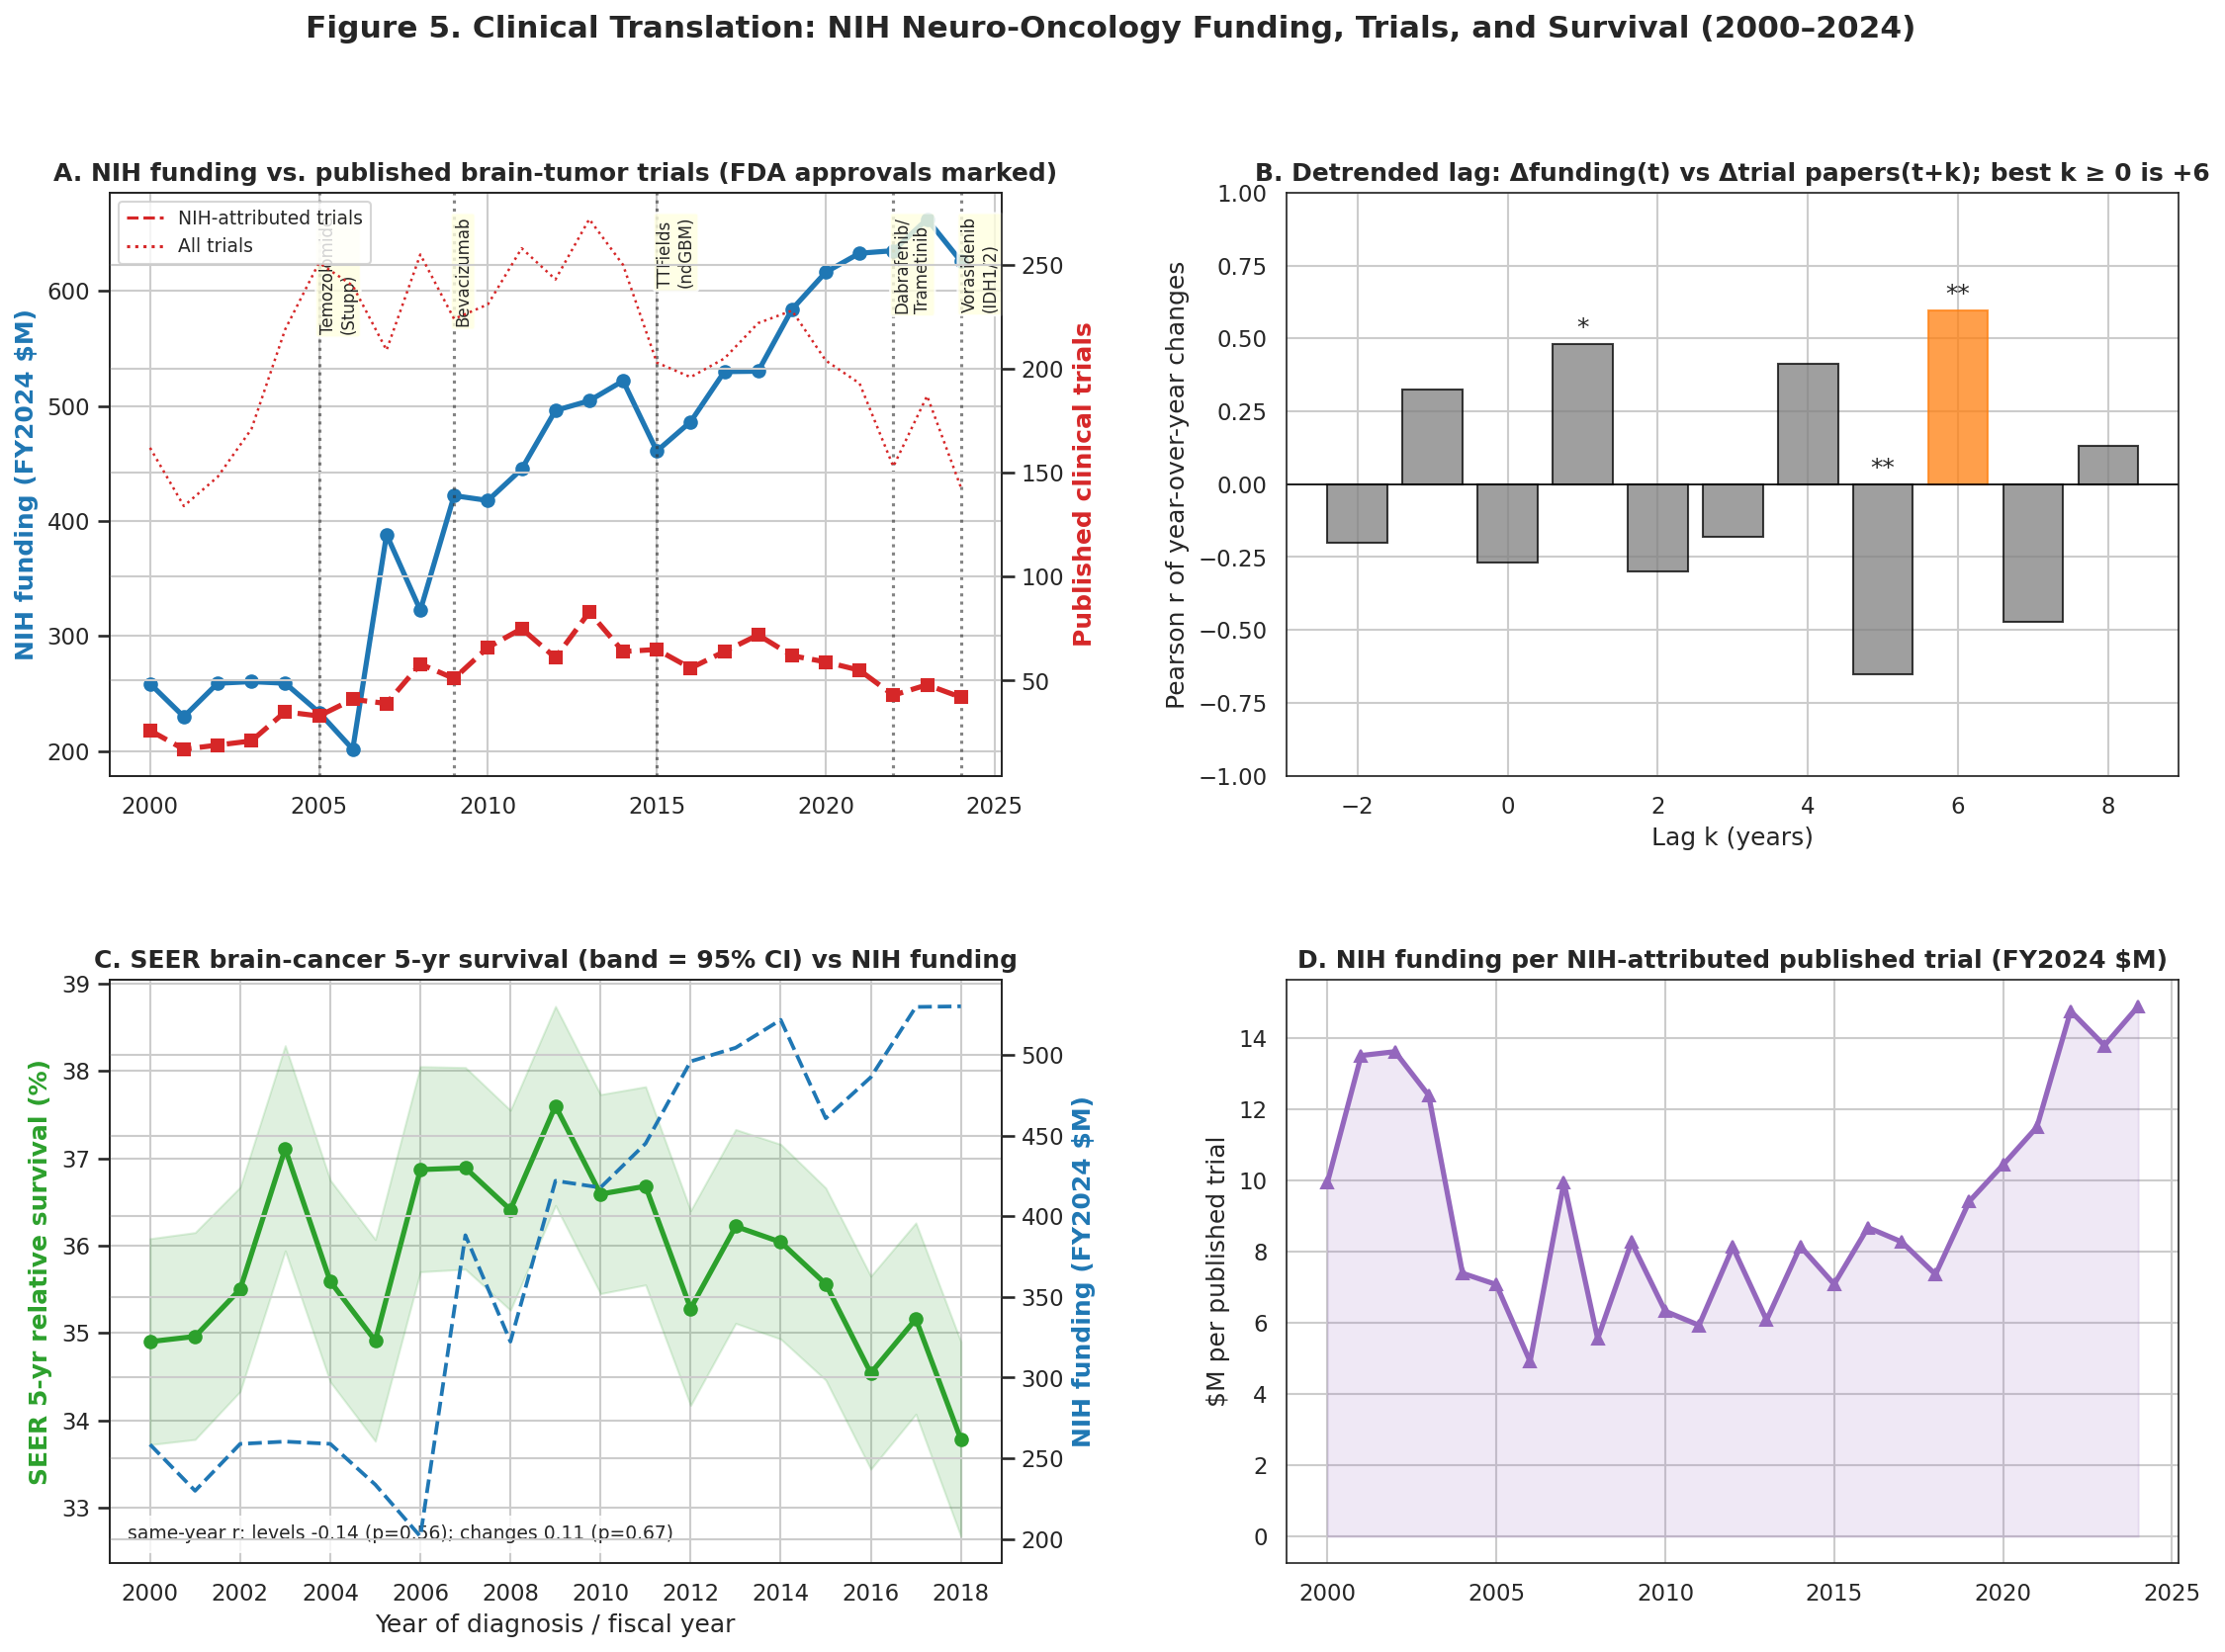

,Lag,r,p,n
0,-2,-0.200,0.372,22
1,-1,0.324,0.132,23
2,0,-0.267,0.206,24
3,1,0.481,0.020,23
4,2,-0.301,0.174,22
5,3,-0.180,0.436,21
6,4,0.412,0.071,20
7,5,-0.652,0.003,19
8,6,0.598,0.009,18
9,7,-0.473,0.055,17


In [32]:
lags = list(range(-2, 9))
ccf_trial = lag_ccf(df_clin["Funding_Const_M"], df_clin["Pub_Any trial_NIH"], lags)
pos = ccf_trial[ccf_trial["Lag"] >= 0]
best_trial_lag = int(pos.loc[pos["r"].idxmax(), "Lag"])

fig, axes = plt.subplots(2, 2, figsize=(18, 12), dpi=150)
plt.subplots_adjust(hspace=0.35, wspace=0.32)

ax = axes[0, 0]; ax2 = ax.twinx()
ax.plot(df_clin.index, df_clin["Funding_Const_M"], color="#1f77b4", lw=2.5, marker="o")
ax2.plot(df_clin.index, df_clin["Pub_Any trial_NIH"], color="#d62728", lw=2.5, ls="--", marker="s")
ax2.plot(df_clin.index, df_clin["Pub_Any trial"], color="#d62728", lw=1.2, ls=":")
milestones = {2005: "Temozolomide\n(Stupp)", 2009: "Bevacizumab", 2015: "TTFields\n(ndGBM)",
              2022: "Dabrafenib/\nTrametinib", 2024: "Vorasidenib\n(IDH1/2)"}
for yr, label in milestones.items():
    if START_YEAR <= yr <= END_YEAR:
        ax.axvline(yr, color="#333333", ls=":", alpha=0.6)
        ax.text(yr, ax.get_ylim()[1] * 0.97, label, rotation=90, fontsize=8, va="top",
                bbox=dict(boxstyle="round,pad=0.2", fc="lightyellow", alpha=0.8))
ax.set_ylabel(f"NIH funding (FY{DOLLAR_YEAR} $M)", color="#1f77b4", fontweight="bold")
ax2.set_ylabel("Published clinical trials", color="#d62728", fontweight="bold")
ax2.legend([plt.Line2D([], [], color="#d62728", ls="--"), plt.Line2D([], [], color="#d62728", ls=":")],
           ["NIH-attributed trials", "All trials"], loc="upper left", fontsize=9)
ax.set_title("A. NIH funding vs. published brain-tumor trials (FDA approvals marked)", fontweight="bold")

ax = axes[0, 1]
bars = ax.bar(ccf_trial["Lag"], ccf_trial["r"], color="#7f7f7f", alpha=0.75, edgecolor="black")
bars[lags.index(best_trial_lag)].set_color("#ff7f0e")
for _, r in ccf_trial.iterrows():
    ax.text(r["Lag"], (r["r"] if r["r"] > 0 else 0) + 0.03, stars(r["p"]), ha="center")
ax.axhline(0, color="black", lw=0.8); ax.set_ylim(-1, 1)
ax.set_title(f"B. Detrended lag: Δfunding(t) vs Δtrial papers(t+k); best k ≥ 0 is +{best_trial_lag}", fontweight="bold")
ax.set_xlabel("Lag k (years)"); ax.set_ylabel("Pearson r of year-over-year changes")

ax = axes[1, 0]; axr = ax.twinx()
ax.plot(seer.index, seer.values, color="#2ca02c", lw=2.5, marker="o", label="5-yr relative survival (%)")
if {"CI_low", "CI_high"} <= set(seer_full.columns):
    ax.fill_between(seer_full.index, seer_full["CI_low"], seer_full["CI_high"], color="#2ca02c", alpha=0.15)
fund_overlap = df_clin.loc[df_clin.index.isin(seer.index), "Funding_Const_M"]
axr.plot(fund_overlap.index, fund_overlap.values, color="#1f77b4", lw=1.8, ls="--", label="NIH funding")
j = pd.concat([fund_overlap.rename("F"), seer.rename("S")], axis=1).dropna()
r_lvl, p_lvl = stats.pearsonr(j["F"], j["S"]) if len(j) > 5 else (np.nan, np.nan)
dj = j.diff().dropna()
r_chg, p_chg = stats.pearsonr(dj["F"], dj["S"]) if len(dj) > 5 else (np.nan, np.nan)
ax.text(0.02, 0.04, f"same-year r: levels {r_lvl:.2f} (p={p_lvl:.2f}); changes {r_chg:.2f} (p={p_chg:.2f})",
        transform=ax.transAxes, fontsize=9, bbox=dict(fc="white", alpha=0.8))
ax.set_ylabel("SEER 5-yr relative survival (%)", color="#2ca02c", fontweight="bold")
axr.set_ylabel(f"NIH funding (FY{DOLLAR_YEAR} $M)", color="#1f77b4", fontweight="bold")
ax.set_xlabel("Year of diagnosis / fiscal year")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_title("C. SEER brain-cancer 5-yr survival (band = 95% CI) vs NIH funding", fontweight="bold")

ax = axes[1, 1]
per_trial = df_clin["Funding_Const_M"] / df_clin["Pub_Any trial_NIH"].replace(0, np.nan)
ax.plot(df_clin.index, per_trial, color="#9467bd", lw=2.5, marker="^")
ax.fill_between(df_clin.index, per_trial, color="#9467bd", alpha=0.15)
ax.set_title(f"D. NIH funding per NIH-attributed published trial (FY{DOLLAR_YEAR} $M)", fontweight="bold")
ax.set_ylabel("$M per published trial")

fig.suptitle(f"Figure 5. Clinical Translation: NIH Neuro-Oncology Funding, Trials, and Survival ({START_YEAR}–{END_YEAR})",
             fontsize=15, fontweight="bold", y=0.98)
save(fig, "fig5_clinical_translation")
plt.show()
display(ccf_trial.round(3))

#Figure 5: Figure 5. Clinical Translation: NIH Neuro-Oncology Funding, Trials, and Survival
- **A.** Brain-tumor NIH money (blue) versus published brain-tumor clinical trials (red), with dotted vertical lines marking major FDA drug approvals.
- **B.** Whether a jump in funding is followed by a jump in published trials *k* years later: taller bars mean a stronger link, and stars mark links unlikely to be chance.
- **C.** The percentage of brain-cancer patients alive 5 years after diagnosis, by year diagnosed (green, with the shaded band showing uncertainty), next to NIH funding (blue dashed). Survival rose until about 2011 and then slipped, so it has not simply tracked funding.
- **D.** How many NIH dollars it takes per published brain-tumor trial each year; higher means each trial costs more.

# 6. Registered Trials (ClinicalTrials.gov) vs. Published Trials

This section pulls every interventional brain-tumor study registered on ClinicalTrials.gov with a start date between 2000 and 2024, and tabulates the studies by start year and phase. It compares registrations with published trials by phase, which tests whether the early-phase publication signal matches what is actually being started.

Caveats:
- Registration only became expected in 2005 (ICMJE policy) and legally required for many trials in 2007 (FDAAA), so the early years are undercounted.
- The phase ratios in Panel C describe the *mix* of new trials. They are not true drug-by-drug progression, which would require matching the same intervention across Phase I, II, and III records.

In [33]:
CT_COND = ("brain tumor OR brain neoplasm OR glioma OR glioblastoma OR medulloblastoma OR "
           "ependymoma OR brain metastases OR CNS tumor")

def ctgov_studies():
    def fetch():
        studies, token = [], None
        while True:
            params = {"query.cond": CT_COND,
                      "filter.advanced": f"AREA[StudyType]INTERVENTIONAL AND AREA[StartDate]RANGE[{START_YEAR}-01-01,{END_YEAR}-12-31]",
                      "fields": "NCTId,Phase,StartDate,OverallStatus,LeadSponsorClass",
                      "pageSize": 1000}
            if token:
                params["pageToken"] = token
            data = _request("GET", CTGOV, 0.5, params=params)
            studies += data.get("studies", [])
            token = data.get("nextPageToken")
            if not token:
                break
        return studies
    return _cached("ctgov", [CT_COND, START_YEAR, END_YEAR], fetch)

def _get(d, *keys):
    for k in keys:
        d = d.get(k) if isinstance(d, dict) else None
    return d

def phase_label(phases):
    ph = set(phases or [])
    early = bool(ph & {"EARLY_PHASE1", "PHASE1"})
    if early and "PHASE2" in ph: return "Phase I/II"
    if "PHASE2" in ph and "PHASE3" in ph: return "Phase II/III"
    if early: return "Phase I"
    if "PHASE2" in ph: return "Phase II"
    if "PHASE3" in ph: return "Phase III"
    if "PHASE4" in ph: return "Phase IV"
    return "Not applicable"

raw = ctgov_studies()
ct = pd.DataFrame([{
    "nct": _get(s, "protocolSection", "identificationModule", "nctId"),
    "phase": phase_label(_get(s, "protocolSection", "designModule", "phases")),
    "start": _get(s, "protocolSection", "statusModule", "startDateStruct", "date"),
    "status": _get(s, "protocolSection", "statusModule", "overallStatus"),
    "sponsor": _get(s, "protocolSection", "sponsorCollaboratorsModule", "leadSponsor", "class"),
} for s in raw])
log_flow("ClinicalTrials.gov", "Interventional brain-tumor studies identified", len(ct))
ct = ct.dropna(subset=["nct", "start"]).drop_duplicates("nct")
ct["Year"] = ct["start"].str[:4].astype(int)
ct = ct[ct["Year"].between(START_YEAR, END_YEAR)]
log_flow("ClinicalTrials.gov", "Unique studies with valid start year (included)", len(ct))
ct.to_csv(os.path.join(DATA_DIR, "ctgov_brain_tumor_trials.csv"), index=False)

PHASE_ORDER = ["Phase I", "Phase I/II", "Phase II", "Phase II/III", "Phase III"]
reg = ct.pivot_table(index="Year", columns="phase", values="nct", aggfunc="count").reindex(YEARS).fillna(0)
for p in PHASE_ORDER + ["Phase IV", "Not applicable"]:
    if p not in reg:
        reg[p] = 0
print(f"{len(ct)} registered interventional brain-tumor studies; by phase:")
display(ct["phase"].value_counts())

5279 registered interventional brain-tumor studies; by phase:


,count
phase,
Phase II,1494
Not applicable,1431
Phase I,1274
Phase I/II,518
Phase III,354
Phase IV,149
Phase II/III,59


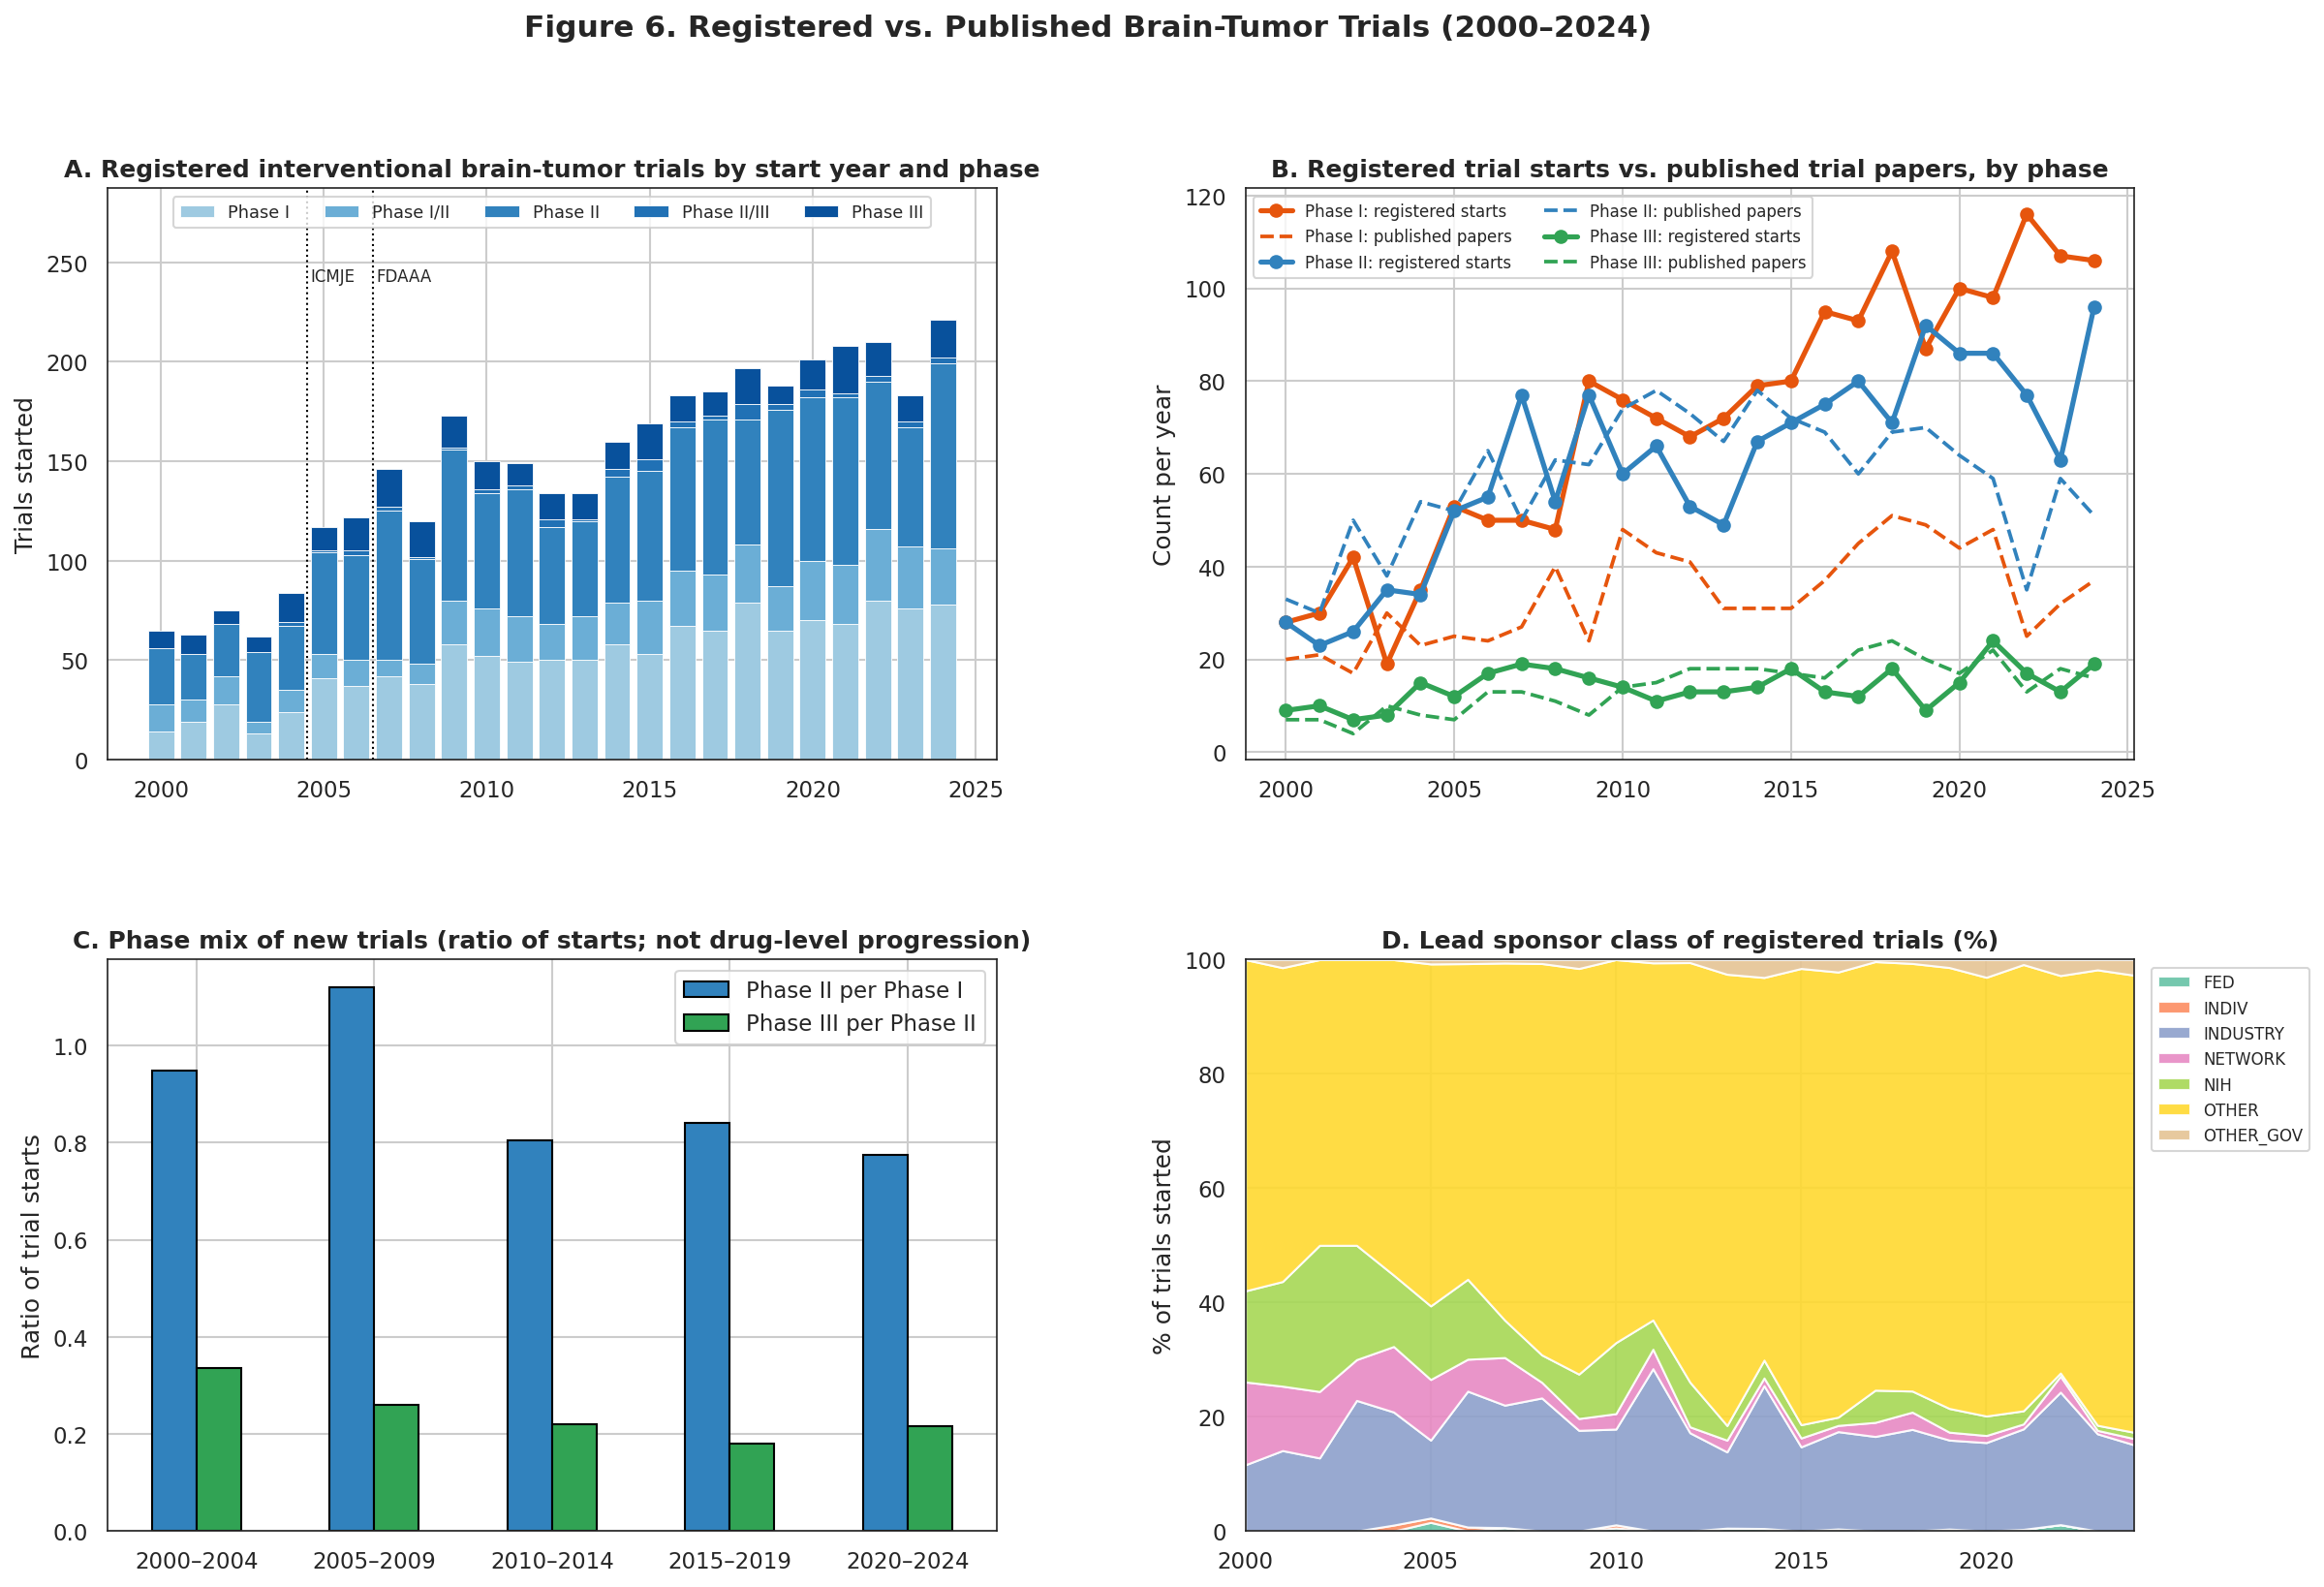

Detrended lag: Δregistered starts(t) vs Δpublished papers(t+k)


Phase I        Phase II        Phase III       
          r      p        r      p         r      p
Lag                                                
0    -0.526  0.008   -0.295  0.162     0.316  0.132
1     0.537  0.008    0.108  0.624    -0.466  0.025
2    -0.215  0.336   -0.102  0.650    -0.058  0.796
3     0.401  0.071   -0.068  0.771     0.460  0.036
4    -0.426  0.061    0.261  0.267    -0.366  0.112
5    -0.015  0.952    0.056  0.819     0.031  0.898
6     0.169  0.504   -0.197  0.433     0.402  0.098

,Phase II per Phase I,Phase III per Phase II
2000–2004,0.95,0.34
2005–2009,1.12,0.26
2010–2014,0.80,0.22
2015–2019,0.84,0.18
2020–2024,0.77,0.22


In [34]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12), dpi=150)
plt.subplots_adjust(hspace=0.35, wspace=0.28)
pcolors = dict(zip(PHASE_ORDER, ["#9ecae1", "#6baed6", "#3182bd", "#2171b5", "#08519c"]))

ax = axes[0, 0]
bottom = np.zeros(len(reg))
for p in PHASE_ORDER:
    ax.bar(reg.index, reg[p], bottom=bottom, color=pcolors[p], label=p, edgecolor="white", linewidth=0.4)
    bottom += reg[p].values
ax.set_ylim(0, bottom.max() * 1.3)
for yr, lab in [(2005, "ICMJE"), (2007, "FDAAA")]:
    ax.axvline(yr - 0.5, color="black", ls=":", lw=1)
    ax.text(yr - 0.4, bottom.max() * 1.12, lab, fontsize=8, va="top")
ax.set_title("A. Registered interventional brain-tumor trials by start year and phase", fontweight="bold")
ax.set_ylabel("Trials started"); ax.legend(fontsize=8.5, ncol=5, loc="upper center")

ax = axes[0, 1]
reg_simple = pd.DataFrame({"Phase I": reg["Phase I"] + reg["Phase I/II"],
                           "Phase II": reg["Phase II"] + reg["Phase II/III"],
                           "Phase III": reg["Phase III"]})
for p, c in zip(["Phase I", "Phase II", "Phase III"], ["#e6550d", "#3182bd", "#31a354"]):
    ax.plot(reg_simple.index, reg_simple[p], color=c, lw=2.5, marker="o", label=f"{p}: registered starts")
    ax.plot(df_clin.index, df_clin[f"Pub_{p}"], color=c, lw=1.8, ls="--", label=f"{p}: published papers")
ax.set_title("B. Registered trial starts vs. published trial papers, by phase", fontweight="bold")
ax.set_ylabel("Count per year"); ax.legend(fontsize=8, ncol=2)

ax = axes[1, 0]
periods = pd.cut(reg_simple.index, bins=range(START_YEAR, END_YEAR + 6, 5), right=False,
                 labels=[f"{b}–{min(b+4, END_YEAR)}" for b in range(START_YEAR, END_YEAR + 1, 5)])
per = reg_simple.groupby(periods, observed=False).sum()
ratio = pd.DataFrame({"Phase II per Phase I": per["Phase II"] / per["Phase I"].replace(0, np.nan),
                      "Phase III per Phase II": per["Phase III"] / per["Phase II"].replace(0, np.nan)})
ratio.plot.bar(ax=ax, color=["#3182bd", "#31a354"], edgecolor="black", rot=0)
ax.set_title("C. Phase mix of new trials (ratio of starts; not drug-level progression)", fontweight="bold")
ax.set_ylabel("Ratio of trial starts")

ax = axes[1, 1]
spons = ct.pivot_table(index="Year", columns="sponsor", values="nct", aggfunc="count").reindex(YEARS).fillna(0)
spons_pct = spons.div(spons.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) * 100
ax.stackplot(spons_pct.index, spons_pct.T, labels=spons_pct.columns,
             colors=sns.color_palette("Set2", len(spons_pct.columns)), alpha=0.9)
ax.set_xlim(START_YEAR, END_YEAR); ax.set_ylim(0, 100)
ax.set_title("D. Lead sponsor class of registered trials (%)", fontweight="bold")
ax.set_ylabel("% of trials started"); ax.legend(loc="upper left", fontsize=8, bbox_to_anchor=(1.01, 1))

fig.suptitle(f"Figure 6. Registered vs. Published Brain-Tumor Trials ({START_YEAR}–{END_YEAR})",
             fontsize=15, fontweight="bold", y=0.98)
save(fig, "fig6_registered_vs_published_trials")
plt.show()

print("Detrended lag: Δregistered starts(t) vs Δpublished papers(t+k)")
reg_pub_lag = pd.concat({p: lag_ccf(reg_simple[p], df_clin[f"Pub_{p}"], range(0, 7)).set_index("Lag")[["r", "p"]]
                         for p in ["Phase I", "Phase II", "Phase III"]}, axis=1)
display(reg_pub_lag.round(3))
display(ratio.round(2))

#Figure 6: Registered vs Published Brain Tumor Trials
A. How many brain-tumor treatment trials were registered as starting each year, colored by phase from small early safety studies (light blue) to large Phase III trials (dark blue). Bars before 2005–2007 are undercounted because registration wasn't yet required.

B. Solid lines count trials started each year and dashed lines count trial papers published, by phase; a dashed line far above its solid line means papers outnumber genuinely new trials.

C. For every Phase I trial started, how many Phase II trials started (blue), and Phase III per Phase II (green). These are rough signs of how much activity reaches later stages, not true drug-by-drug tracking.

D. Who runs the trials each year (NIH, drug companies, cooperative networks, or universities and hospitals) as a share of all trials.

# 7. Data Flow (PRISMA-style) and Key Numbers for the Abstract

The data-flow table lists records identified and records retained after deduplication for each source. The block below it prints every number the abstract and conclusion cite, so the text can be filled in from this run.

In [23]:
df_flow = pd.DataFrame(FLOW)
df_flow.to_csv(os.path.join(DATA_DIR, "data_flow.csv"), index=False)
display(df_flow)

f0, f1 = df_no.loc[START_YEAR], df_no.loc[END_YEAR]
print("=" * 70)
print("KEY NUMBERS")
print("=" * 70)
print(f"Neuro-onc NIH funding: ${f0['Funding_Const_M']:.0f}M → ${f1['Funding_Const_M']:.0f}M (FY{DOLLAR_YEAR} $); "
      f"nominal ${f0['Funding_Nominal_M']:.0f}M → ${f1['Funding_Nominal_M']:.0f}M")
print(f"Neuro-onc NIH-attributed papers: {f0['Pubs_NIH']:.0f} → {f1['Pubs_NIH']:.0f}  (all papers {f0['Pubs_All']:.0f} → {f1['Pubs_All']:.0f})")
print(f"Funding per NIH-attributed paper: ${1e3*f0['Funding_Const_M']/f0['Pubs_NIH']:.0f}k → ${1e3*f1['Funding_Const_M']/f1['Pubs_NIH']:.0f}k (FY{DOLLAR_YEAR} $)")
print(f"Best detrended funding→papers lag: +{best_lag_no} yr")
print(f"Granger funding→papers, Holm-adjusted p by lag 1–4: {', '.join(f'{p:.3f}' for p in granger_f2p['p_Holm'])}")
print(f"Granger papers→funding, Holm-adjusted p by lag 1–4: {', '.join(f'{p:.3f}' for p in granger_p2f['p_Holm'])}")
print(f"Paradigm-level optimal lag (computed): +{OPT_LAG} yr; classified-dollar coverage median {df_cov['Coverage_%'].median():.0f}%")
mi = [m for m in MOD_NAMES if "Molecular" in m or "Immuno" in m]
sr = [m for m in MOD_NAMES if "Surgery" in m or "Radiation" in m]
fcol, pcol = f"% funding {END_YEAR-4}–{END_YEAR}", f"% papers {END_YEAR-4}–{END_YEAR}"
print(f"Molecular + Immunotherapy, {END_YEAR-4}–{END_YEAR}: {paradox.loc[mi, fcol].sum():.0f}% of funding, {paradox.loc[mi, pcol].sum():.0f}% of papers")
print(f"Surgery + Radiation,       {END_YEAR-4}–{END_YEAR}: {paradox.loc[sr, fcol].sum():.0f}% of funding, {paradox.loc[sr, pcol].sum():.0f}% of papers")
for m in MOD_NAMES:
    print(f"  {m}: peak detrended lag +{paradox.loc[m, 'Peak detrended lag']}, r = {paradox.loc[m, 'Peak r']:.2f}, p = {paradox.loc[m, 'Peak p']:.3f}")
pt0, pt1 = per_trial.dropna().iloc[0], per_trial.dropna().iloc[-1]
print(f"Funding per NIH-attributed published trial: ${pt0:.2f}M → ${pt1:.2f}M (FY{DOLLAR_YEAR} $)")
print(f"Best detrended funding→trial-paper lag (k ≥ 0): +{best_trial_lag} yr")
print(f"Registered interventional brain-tumor trials {START_YEAR}–{END_YEAR}: {len(ct)}")
print(f"Neuro-oncology growth IRR vs neurology: {df_growth.set_index('Subspecialty').loc['Neuro-oncology', 'Growth_IRR_vs_neurology']:.3f}")
print("=" * 70)
print(f"Figures saved to ./{FIG_DIR}/  ·  tables saved to ./{DATA_DIR}/")

,Source,Step,Records
0,PubMed: subspecialties (all),Subspecialty matches identified,1484620
1,PubMed: subspecialties (all),Unique papers after cross-subspecialty dedupli...,1365786
2,PubMed: subspecialties (NIH),Subspecialty matches identified,178154
3,PubMed: subspecialties (NIH),Unique papers after cross-subspecialty dedupli...,164859
4,NIH RePORTER: subspecialties,Award matches identified,276887
5,NIH RePORTER: subspecialties,Unique awards after cross-subspecialty dedupli...,219806
6,NIH RePORTER: neuro-oncology,Unique awards (summed over years),17376
7,PubMed: neuro-oncology,"Papers, all (summed over years)",167771
8,PubMed: neuro-oncology,"Papers, NIH-attributed (summed over years)",21745
9,NIH RePORTER: paradigms,Paradigm matches identified,20234


KEY NUMBERS
Neuro-onc NIH funding: $259M → $626M (FY2024 $); nominal $127M → $626M
Neuro-onc NIH-attributed papers: 363 → 1038  (all papers 3278 → 10128)
Funding per NIH-attributed paper: $712k → $603k (FY2024 $)
Best detrended funding→papers lag: +1 yr
Granger funding→papers, Holm-adjusted p by lag 1–4: 0.260, 0.685, 0.685, 0.685
Granger papers→funding, Holm-adjusted p by lag 1–4: 1.000, 1.000, 1.000, 1.000
Paradigm-level optimal lag (computed): +5 yr; classified-dollar coverage median 69%
Molecular + Immunotherapy, 2020–2024: 70% of funding, 59% of papers
Surgery + Radiation,       2020–2024: 25% of funding, 33% of papers
  1. Surgery & Local Control: peak detrended lag +3, r = 0.37, p = 0.103
  2. Radiation & Biophysical: peak detrended lag +5, r = 0.47, p = 0.043
  3. Cytotoxic Chemotherapy: peak detrended lag +3, r = 0.44, p = 0.047
  4. Molecular & Genetic: peak detrended lag +3, r = 0.32, p = 0.151
  5. Immunotherapy & Viral: peak detrended lag +-2, r = 0.31, p = 0.166
Funding p

# Conclusions

These conclusions are written to hold whatever this run's funding numbers turn out to be. The data-dependent claims are stated in *Findings From This Run* above, and the paragraphs below say how to read them.

**1. Raw totals overstate the link between money and science.** NIH funding and paper counts both rise almost every year, so any two such series correlate at r > 0.9 regardless of whether one causes the other (Figure 3B, gray bars). Once the shared trend is removed, the remaining relationship between funding changes and output changes is modest and noisy (orange bars, Findings #3).

The correct conclusion is not that "funding drives publications with an *x*-year lag." It is that, at annual resolution over about 24 years, funding changes explain at most a small share of output changes. That is a limit of national-aggregate data, and it is itself a finding worth reporting.

**2. Survival has not tracked funding.** SEER's real series shows 5-year relative survival for malignant brain tumors rising slowly to about 2011 and then declining, while NIH funding grew in real terms over much of the same period (Figure 5C). The original notebook's claim of r = 0.975 between funding and survival came from invented numbers and should not appear in any abstract.

Two explanations remain open, and Hypothesis H3 below tests between them:
- **Case mix.** An aging population means more glioblastoma among older adults, which would pull the all-tumor average down even if care improved.
- **Genuine stagnation.** Progress may be concentrated in small, biomarker-defined groups that barely move the population average, such as IDH-mutant glioma (vorasidenib, 2024) or BRAF V600E tumors (dabrafenib/trametinib).

**3. How money is split across research approaches.** If Findings #4 says **SUPPORTED**, molecular and immunotherapy research absorbs a larger share of dollars than of papers. The likely reasons are high per-project costs (sequencing, vector manufacturing, cell-therapy production) and long preclinical timelines, not low productivity.

If it says **NOT SUPPORTED**, the earlier "60% of money, under 40% of papers" figure was an artifact of the unpaged, unadjusted data, and the paper should drop the "translation paradox" framing.

**4. Trial cost and pipeline.** Rising funding per published trial (Findings #5) means each NIH dollar produces fewer published trials than it used to. The registered Phase II-to-Phase I ratio shows whether early-phase activity is turning into mid-stage testing or piling up at Phase I.

**5. Neuro-oncology among neurology subspecialties.** Once the outlier Alzheimer's/dementia budget is set aside, neuro-oncology's funding share relative to its paper share (Findings #2) shows whether it is resourced in line with its research output. This is the cross-subspecialty comparison the title promises.



---



# Future Predictions (2026–2035)

Each prediction is written so that re-running this notebook in later years can confirm or refute it.

**P1. Real-dollar NIH neuro-oncology funding will be flat to slightly declining through about 2028.**
- Congress gave NIH $47.2B for FY2026, up $415M (about 0.9%) from FY2025, and NCI $7.35B, up $128M (about 1.8%).
- NIH projects its biomedical inflation index to rise 2.7% for FY2026. In constant dollars, that makes FY2026 a real cut of roughly 2% for NIH and 1% for NCI.
- Congress also blocked the proposed 15% indirect-cost cap and limited the shift to up-front multi-year awards to FY2025 levels. Both would otherwise have reduced the number of grants.
- *Test:* Figure 3A constant-dollar line for FY2026–2028.

**P2. Cost per paper and per published trial will keep rising** (Figures 3D, 5D), because cell therapies, multi-omics, and imaging-guided delivery cost more per project than the drug-plus-radiation studies of the 2000s.

**P3. Trials will shift from "new drug" to "new way to get a drug in."** Recent results point at delivery as the bottleneck:
- **Focused ultrasound.** Opening the blood–brain barrier with MRI-guided focused ultrasound during temozolomide gave 34 patients a median survival over 30 months, versus 19 months in a matched control group. A larger pivotal trial (LIBERATE) has since closed to enrollment.
- **CAR-T.** Bivalent EGFR/IL-13Rα2 CAR-T cells given directly into the brain's fluid spaces shrank tumors in 62% of 18 recurrent-glioblastoma patients. However, median progression-free survival was only 1.9 months.
- *Test:* the share of registered trials whose interventions include focused ultrasound, convection-enhanced, intraventricular, intratumoral, or LITT delivery should rise in Figure 6.

**P4. Platform trials will stop failing drugs earlier and cheaper.** GBM AGILE dropped regorafenib early for lack of benefit (hazard ratios 1.05 and 1.07, no survival gain). Expect more arms per platform, earlier stops, and a falling Phase III-to-Phase II start ratio as weak agents are filtered out at Phase II.

**P5. Population-level brain-cancer survival will stay roughly flat in SEER through the 2025 diagnosis year**, with gains confined to biomarker-defined subgroups, unless a delivery-plus-agent combination succeeds in a pivotal glioblastoma trial.



---



# Where Funding Should Go

These recommendations follow from the evidence above. Where a recommendation depends on this run's results, the relevant finding is named.

**1. Delivery science, paired with agents that already work elsewhere** (highest priority). The survival plateau, the focused-ultrasound result, and repeated failures of systemic drugs in glioblastoma all point to the same problem: drugs and cells do not reach the tumor in adequate amounts. Priorities:
- Focused-ultrasound barrier opening.
- Convection-enhanced and intraventricular delivery.
- Engineering cell therapies to persist in the brain.

This is the strongest case in the paper and does not depend on the paradox result.

**2. Durability of cell therapies, not just first response.** The CAR-T results show the tumor can be hit, since most patients' tumors shrank, but the effect fades within weeks. Funding should target antigen escape (tumors stop displaying the target), T-cell exhaustion, and repeat dosing, measured against progression-free survival rather than radiographic response.

**3. Shared trial infrastructure over isolated grants.** Platform trials (GBM AGILE), "Phase 0" window-of-opportunity studies (which confirm a drug reaches the tumor before a large trial), and cooperative-group networks lower the cost per answered question. This matters most if Findings #5 shows rising cost per trial or a weak Phase II-to-Phase I ratio.

**4. Rebalance only if the data say so.**
- If Findings #4 is SUPPORTED, shift some molecular and immunotherapy discovery funding toward the translational steps above. The goal is to give expensive biology a delivery route, not to cut it.
- If Findings #2 shows neuro-oncology receiving less funding than its share of output (excluding dementia), that is an argument for raising its overall share, not just re-dividing it.

**5. Data infrastructure for measuring translation.** No public dataset currently links an NIH grant to a trial to a patient outcome. Funding the linkage of RePORTER awards, ClinicalTrials.gov records, and SEER/CBTRUS subtype-specific survival would make questions like this paper's answerable directly, rather than through national aggregates.



---



# Future Hypotheses to Test

**H1 — Translational conversion by paradigm (testable with this notebook's data sources).**
- *Prediction:* Phase I/II trial publications per $100M of constant-dollar NIH funding declined between 2010 and 2024 more steeply in the Molecular/Genetic and Immunotherapy paradigms than in Surgery/Radiation.
- *Method:* Restrict each paradigm's PubMed query to `"Clinical Trial, Phase I"[pt] OR "Clinical Trial, Phase II"[pt]`. Fit a Poisson model of trial publications by paradigm and period, offset by log(paradigm funding) at the empirically estimated lag (Figure 4), rather than an assumed +4 years.
- *Support:* a significant paradigm × period interaction (p < 0.05).

**H2 — Delivery-combination trials progress further.**
- *Prediction:* Among registered interventional brain-tumor trials, those whose interventions include a delivery modality (focused ultrasound, convection-enhanced, intraventricular/intratumoral, LITT) are more likely to be followed within 5 years by a registered Phase II trial of the same agent than systemic-only trials.
- *Method:* Drug-level linkage of ClinicalTrials.gov records by intervention name. This is the true "pipeline progression" analysis that Figure 6C approximates.
- *Secondary outcome:* Relative Citation Ratio (iCite) of grants funding such combinations, compared with single-modality grants.

**H3 — Why survival fell after 2011.**
- *Prediction:* The post-2011 decline in all-ages 5-year relative survival for malignant brain tumors is explained by case mix (older age at diagnosis and a larger glioblastoma share), not worsening survival within age and histology groups.
- *Method:* Use SEER*Explorer's histology-specific (glioblastoma, other glioma) and age-stratified series. If within-group survival is flat or rising while the overall rate falls, case mix explains the decline.
- *Why it matters:* this decides whether Conclusion 2 reads "treatment has stalled" or "the patient population has changed."